In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

import matplotlib as mpl
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet'
df = pd.read_parquet(file, engine='pyarrow')

file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_grouped_2hour_pulses.parquet'
groups_df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df.head()

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas
1,36.05,-91.05,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,47.916667,0.0,33.333333,0.000000,2.083333,Arkansas
2,36.05,-90.95,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,1.515152,0.0,46.212121,22.727273,26.515152,Arkansas
3,36.05,-90.85,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,8.333333,0.0,65.972222,2.777778,11.805556,Arkansas
4,36.05,-90.75,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,1.515152,0.0,76.515152,0.000000,4.545455,Arkansas


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name'],
      dtype='object')

In [5]:
groups_df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class,time_num,group_id
0,37.35,-100.85,0.000,2024-03-13 16:00:00,2.173031e+15,6.369229e+14,1.273846e+14,0.0,0.0,0.293103,...,0.000000,0.0,75.000000,0.000000,22.727273,Kansas,-0.000005,decreasing,0.0,0
1,39.35,-92.75,0.000,2024-03-16 15:00:00,4.694567e+15,8.246832e+14,1.649366e+14,0.0,0.0,0.175668,...,0.000000,0.0,77.272727,0.000000,20.454545,Missouri,0.000689,increasing,71.0,1
2,39.15,-92.95,0.000,2024-03-16 15:00:00,2.622688e+15,1.454574e+15,2.969137e+14,0.0,0.0,0.554612,...,5.303030,0.0,71.969697,2.272727,11.363636,Missouri,0.000744,increasing,71.0,3
3,39.15,-92.85,0.000,2024-03-16 15:00:00,2.632403e+15,1.870482e+15,3.740963e+14,0.0,0.0,0.710561,...,1.388889,0.0,88.888889,0.694444,4.166667,Missouri,0.000872,increasing,71.0,3
4,39.15,-93.15,0.000,2024-03-16 15:00:00,2.643212e+15,1.089365e+15,2.178731e+14,0.0,0.0,0.412137,...,0.000000,0.0,100.000000,0.000000,0.000000,Missouri,0.000546,increasing,71.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2004,40.85,-95.05,0.000,2024-07-19 15:00:00,3.003975e+15,5.779969e+14,1.155994e+14,0.0,0.0,0.192411,...,0.000000,0.0,9.917355,0.000000,90.082645,Iowa,-0.000296,decreasing,3071.0,2004
2005,40.95,-94.75,0.000,2024-07-19 16:00:00,2.530260e+15,9.967452e+14,2.417462e+14,0.0,0.0,0.393930,...,0.000000,0.0,14.583333,0.000000,84.722222,Iowa,-0.000236,decreasing,3072.0,2005
2006,37.55,-98.35,0.105,2024-07-19 18:00:00,2.812737e+15,7.392236e+14,1.478447e+14,0.0,0.0,0.262813,...,45.454545,0.0,11.570248,0.000000,0.000000,Kansas,0.000606,increasing,3074.0,2006
2007,37.75,-98.65,0.000,2024-07-19 18:00:00,2.959582e+15,9.768195e+14,1.953639e+14,0.0,0.0,0.330053,...,81.818182,0.0,0.000000,0.000000,0.000000,Kansas,-0.000047,decreasing,3074.0,2007


In [6]:
groups_df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class',
       'time_num', 'group_id'],
      dtype='object')

In [7]:
pulse_df = df.copy()

# keep only true pulse starts
pulse_df = pulse_df[pulse_df["pulse_start"] == True].copy()

# make sure datetime_local is datetime
pulse_df["datetime_local"] = pd.to_datetime(pulse_df["datetime_local"])

# derive time fields
pulse_df["hour_local"] = pulse_df["datetime_local"].dt.hour
pulse_df["date_local"] = pulse_df["datetime_local"].dt.date
pulse_df["month"] = pulse_df["datetime_local"].dt.month
pulse_df["month_name"] = pulse_df["datetime_local"].dt.strftime("%b")
pulse_df["day_of_year"] = pulse_df["datetime_local"].dt.dayofyear

print("Number of pulse starts:", len(pulse_df))
pulse_df.head()

Number of pulse starts: 2009


,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,hour_local,date_local,month,month_name,day_of_year
2778774,37.35,-100.85,0.0,2024-03-13 16:00:00,2.173031e+15,6.369229e+14,1.273846e+14,0.0,0.0,0.293103,...,0.0,75.000000,0.000000,22.727273,Kansas,11,2024-03-13,3,Mar,73
3424119,39.15,-93.95,0.0,2024-03-16 15:00:00,4.878880e+15,1.483211e+15,3.092709e+14,0.0,0.0,0.304006,...,0.0,62.500000,2.777778,25.694444,Missouri,10,2024-03-16,3,Mar,76
3424120,39.15,-93.85,0.0,2024-03-16 15:00:00,4.200688e+15,1.569941e+15,3.347125e+14,0.0,0.0,0.373734,...,0.0,62.121212,0.000000,35.606061,Missouri,10,2024-03-16,3,Mar,76
3424127,39.15,-93.15,0.0,2024-03-16 15:00:00,2.643212e+15,1.089365e+15,2.178731e+14,0.0,0.0,0.412137,...,0.0,100.000000,0.000000,0.000000,Missouri,10,2024-03-16,3,Mar,76
3424129,39.15,-92.95,0.0,2024-03-16 15:00:00,2.622688e+15,1.454574e+15,2.969137e+14,0.0,0.0,0.554612,...,0.0,71.969697,2.272727,11.363636,Missouri,10,2024-03-16,3,Mar,76


In [8]:
pulse_df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,hour_local,date_local,month,month_name,day_of_year
2778774,37.35,-100.85,0.000,2024-03-13 16:00:00,2.173031e+15,6.369229e+14,1.273846e+14,0.0,0.0,0.293103,...,0.0,75.000000,0.000000,22.727273,Kansas,11,2024-03-13,3,Mar,73
3424119,39.15,-93.95,0.000,2024-03-16 15:00:00,4.878880e+15,1.483211e+15,3.092709e+14,0.0,0.0,0.304006,...,0.0,62.500000,2.777778,25.694444,Missouri,10,2024-03-16,3,Mar,76
3424120,39.15,-93.85,0.000,2024-03-16 15:00:00,4.200688e+15,1.569941e+15,3.347125e+14,0.0,0.0,0.373734,...,0.0,62.121212,0.000000,35.606061,Missouri,10,2024-03-16,3,Mar,76
3424127,39.15,-93.15,0.000,2024-03-16 15:00:00,2.643212e+15,1.089365e+15,2.178731e+14,0.0,0.0,0.412137,...,0.0,100.000000,0.000000,0.000000,Missouri,10,2024-03-16,3,Mar,76
3424129,39.15,-92.95,0.000,2024-03-16 15:00:00,2.622688e+15,1.454574e+15,2.969137e+14,0.0,0.0,0.554612,...,0.0,71.969697,2.272727,11.363636,Missouri,10,2024-03-16,3,Mar,76
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30699707,41.05,-95.25,0.000,2024-07-19 15:00:00,3.562067e+15,1.676264e+15,4.065537e+14,0.0,0.0,0.470587,...,0.0,9.917355,0.000000,90.082645,Iowa,10,2024-07-19,7,Jul,201
30708663,40.95,-94.75,0.000,2024-07-19 16:00:00,2.530260e+15,9.967452e+14,2.417462e+14,0.0,0.0,0.393930,...,0.0,14.583333,0.000000,84.722222,Iowa,11,2024-07-19,7,Jul,201
30724201,37.55,-98.35,0.105,2024-07-19 18:00:00,2.812737e+15,7.392236e+14,1.478447e+14,0.0,0.0,0.262813,...,0.0,11.570248,0.000000,0.000000,Kansas,13,2024-07-19,7,Jul,201
30724264,37.75,-98.65,0.000,2024-07-19 18:00:00,2.959582e+15,9.768195e+14,1.953639e+14,0.0,0.0,0.330053,...,0.0,0.000000,0.000000,0.000000,Kansas,13,2024-07-19,7,Jul,201


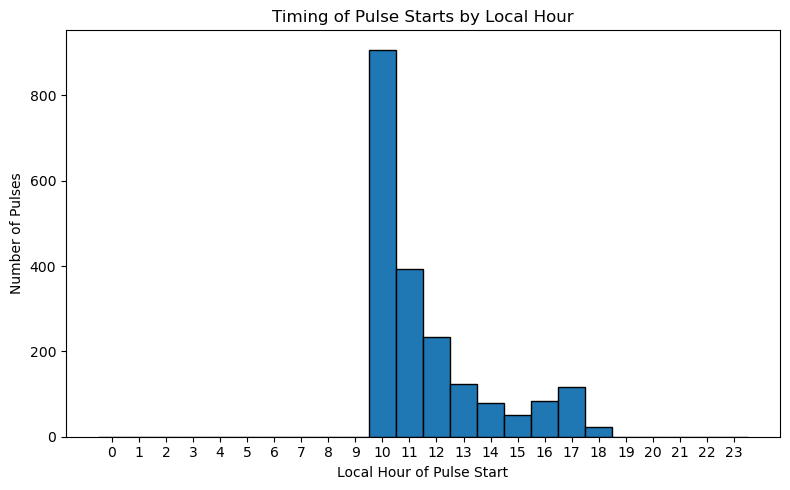

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(pulse_df["hour_local"], bins=range(0, 25), edgecolor="black", align="left")
plt.xticks(range(0, 24))
plt.xlabel("Local Hour of Pulse Start")
plt.ylabel("Number of Pulses")
plt.title("Timing of Pulse Starts by Local Hour")
plt.tight_layout()
plt.show()

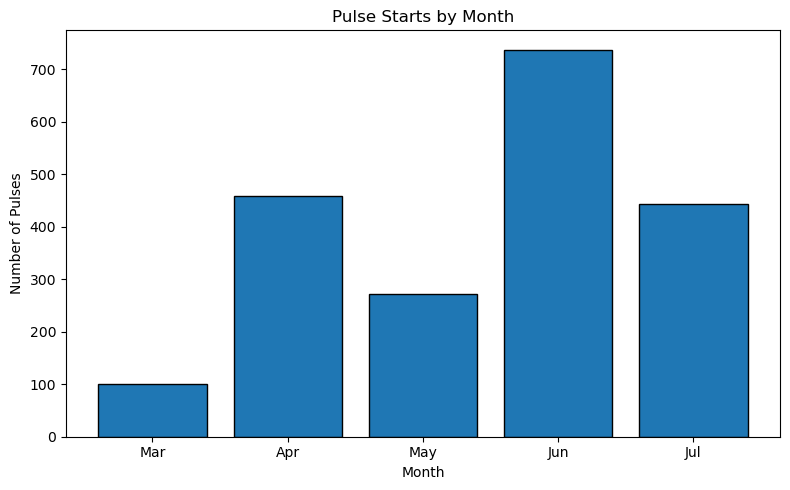

In [10]:
month_counts = (
    pulse_df.groupby(["month", "month_name"])
    .size()
    .reset_index(name="count")
    .sort_values("month")
)

plt.figure(figsize=(8, 5))
plt.bar(month_counts["month_name"], month_counts["count"], edgecolor="black")
plt.xlabel("Month")
plt.ylabel("Number of Pulses")
plt.title("Pulse Starts by Month")
plt.tight_layout()
plt.show()

retrying rainfall and pulses idea 

In [11]:
df = df.copy()

# ensure datetime is datetime
df["datetime"] = pd.to_datetime(df["datetime"])

# sort properly
df = df.sort_values(["grid_lat", "grid_lon", "datetime"])

# fill missing precip with 0 (important!)
df["h_precip_mm"] = df["h_precip_mm"].fillna(0)

In [12]:
# group by grid cell
grouped = df.groupby(["grid_lat", "grid_lon"])

# rolling precipitation
df["precip_3d"] = grouped["h_precip_mm"].transform(
    lambda x: x.rolling(window=72, min_periods=1).sum()
)

df["precip_5d"] = grouped["h_precip_mm"].transform(
    lambda x: x.rolling(window=120, min_periods=1).sum()
)

In [13]:
df["precip_3d"] = grouped["precip_3d"].shift(1)
df["precip_5d"] = grouped["precip_5d"].shift(1)

In [14]:
pulse_df = df[df["pulse_start"] == True].copy()

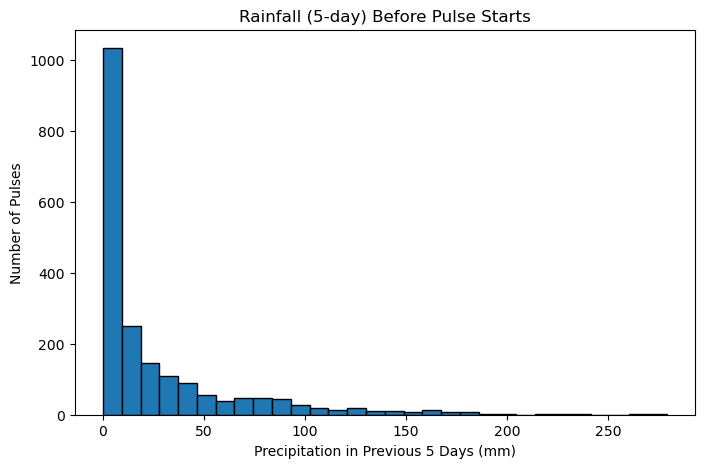

In [15]:
plt.figure(figsize=(8,5))
plt.hist(pulse_df["precip_5d"], bins=30, edgecolor="black")
plt.xlabel("Precipitation in Previous 5 Days (mm)")
plt.ylabel("Number of Pulses")
plt.title("Rainfall (5-day) Before Pulse Starts")
plt.show()

In [16]:
bins = [0, 1, 5, 10, 20, 50, 100]
labels = ["0–1", "1–5", "5–10", "10–20", "20–50", "50+"]

pulse_df["precip_bin_5d"] = pd.cut(
    pulse_df["precip_5d"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

counts = pulse_df["precip_bin_5d"].value_counts().sort_index()

print(counts)

precip_bin_5d
0–1      451
1–5      359
5–10     245
10–20    254
20–50    341
50+      237
Name: count, dtype: int64


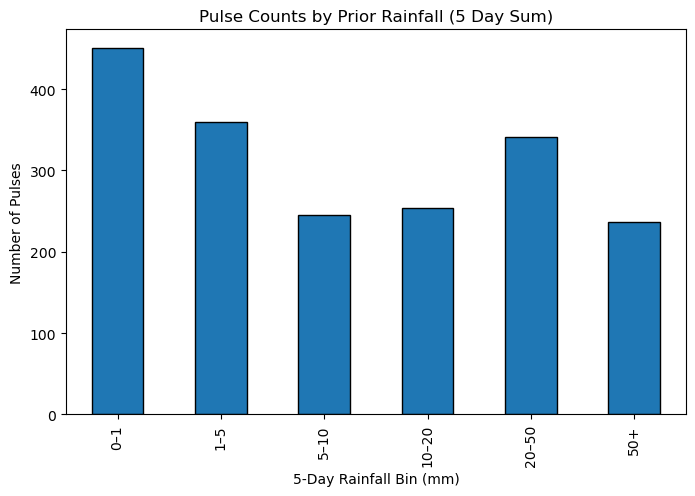

In [17]:
plt.figure(figsize=(8,5))
counts.plot(kind="bar", edgecolor="black")
plt.xlabel("5-Day Rainfall Bin (mm)")
plt.ylabel("Number of Pulses")
plt.title("Pulse Counts by Prior Rainfall (5 Day Sum)")
plt.show()

In [18]:
n = (pulse_df["precip_5d"] > 10).sum()
total = len(pulse_df)

print(f"{n} / {total} pulses ({100*n/total:.1f}%) had >10 mm rainfall in prior 5 days")

954 / 2009 pulses (47.5%) had >10 mm rainfall in prior 5 days


# figure making

In [46]:
bg_color = "blue"   # blue         — background NO2 KDE
color_start= "orange"   # orange       — pulse-start NO2 KDE

# Group-size bin colours (matches your reference figure)
size_bins   = [2, 4, 11, 31, 101]
size_labels = ["1–3", "4–10", "11–30", "31–100"]
size_colors = ["#4472C4", "#ED7D31", "#70AD47", "#FF0000"]

#data prep 
#pulse starts from df 
pulse_df = df[df["pulse_start"] == True].copy()
pulse_df["datetime_local"] = pd.to_datetime(pulse_df["datetime_local"])
pulse_df["_hour"]  = pulse_df["datetime_local"].dt.hour
pulse_df["_month"] = pulse_df["datetime_local"].dt.month

#all unique grid cells 
all_cells = df[["grid_lat", "grid_lon"]].drop_duplicates()

#group size 
group_sizes = (groups_df.groupby("group_id").size().reset_index(name="group_size"))

#center of groups 
group_centroids = (
    groups_df.groupby("group_id")[["grid_lat", "grid_lon"]]
    .mean()
    .reset_index()
    .rename(columns={"grid_lat": "centroid_lat", "grid_lon": "centroid_lon"})
    .merge(group_sizes, on="group_id")
)

# Timing data: merge group_size onto groups_df pulse starts
groups_df["datetime_local"] = pd.to_datetime(groups_df["datetime_local"])
pulse_groups = groups_df[groups_df["pulse_start"] == True].copy()
pulse_groups["_hour"] = groups_df["datetime_local"].dt.hour
pulse_groups["_month"] = groups_df["datetime_local"].dt.month
pulse_groups = pulse_groups.merge(group_sizes, on="group_id")
pulse_groups["size_bin"] = pd.cut(
    pulse_groups["group_size"],
    bins=SIZE_BINS,
    labels=SIZE_LABELS,
    right=False,
)

# NO2 arrays for KDE
bg_vals = df.loc[df["pulse_start"] != True, "no2_mean"].dropna().values
start_vals = pulse_df["no2_mean"].dropna().values

print("Setup complete.")
print(f"Pulse starts:{len(pulse_df):}")
print(f"Pulse groups:{len(group_centroids):}")
print(f"Background obs:{len(bg_vals):}")


Setup complete.
Pulse starts:2009
Pulse groups:777
Background obs:2587507


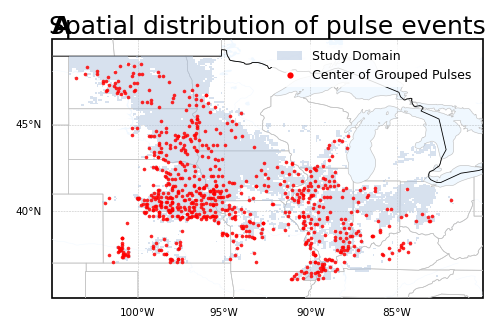

In [44]:
#panel A-- map 
#set parameters
map_extent = [-105, -80, 35, 50]   
domain_alpha= 0.5                  
centroid_size  = 3  
centroid_alpha = 0.85 
gridline_x= range(-110, -75, 5)
gridline_y  =range(35, 55, 5)

cell_w = 0.1 
cell_h= 0.1 


#start figure
proj = ccrs.PlateCarree()
fig_a, ax_map = plt.subplots(figsize=(3.42, 2.6), dpi=150, subplot_kw={"projection": proj})
ax_map.set_extent(map_extent, crs=proj)

#cartopy figures
ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"), facecolor="aliceblue", linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"), edgecolor="aliceblue", linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)

#making rectangles for bg 
rects = []
for lon, lat in zip(all_cells["grid_lon"], all_cells["grid_lat"]):
    rects.append(
        Rectangle(
            (lon - cell_w/2, lat - cell_h/2),
            cell_w,cell_h))

pc = PatchCollection(rects, facecolor="lightsteelblue",edgecolor="none", alpha=domain_alpha, linewidth=0,zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)

#center of grouped puulses 
ax_map.scatter(group_centroids["centroid_lon"], group_centroids["centroid_lat"],
               s=centroid_size, c="red", alpha=centroid_alpha,
               linewidths=0, transform=proj, zorder=8,)

#adding gridlines
gl = ax_map.gridlines(draw_labels=True, linewidth=0.25, color="gray", alpha=0.5, linestyle="--",
                      xlocs=gridline_x, ylocs=gridline_y)
gl.top_labels = False
gl.right_labels= False
gl.xlabel_style= {"size": 5}
gl.ylabel_style= {"size": 5}

#adding legend 
legend_els = [
    Patch(facecolor="lightsteelblue", edgecolor="none", alpha=domain_alpha, label="Study Domain"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markersize=4, label="Center of Grouped Pulses")]


ax_map.legend(handles=legend_els, loc="upper right",frameon=True,framealpha=0.85, edgecolor="none", fontsize=6)

ax_map.set_title("A", loc="left", fontweight="bold", pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

plt.tight_layout()
plt.show()

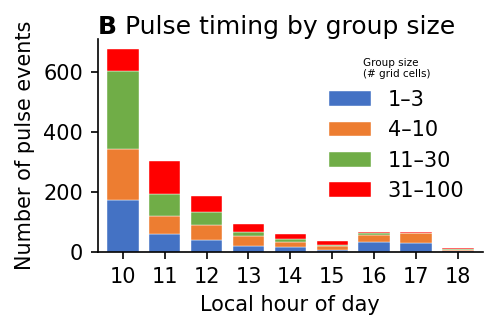

In [48]:
#temporal timing of pulse 

#setting params
hour_min = 10
hour_max = 18
bar_width = 0.75

fig_b, ax_timing = plt.subplots(figsize=(3.42, 2.3), dpi=150)

# Build stacked counts: rows = hours, cols = size bins
stacked = (pulse_groups.groupby(["_hour", "size_bin"], observed=True).size()
           .unstack(fill_value=0).reindex(columns=size_labels, fill_value=0))


# Ensure all hours in range are present
stacked = stacked.reindex(range(hour_min, hour_max + 1), fill_value=0)

bottom = np.zeros(len(stacked))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = stacked[label].values
    ax_timing.bar(
        stacked.index, vals,
        bottom=bottom,
        width=BAR_WIDTH,
        color=color,
        label=label,
        edgecolor="white",
        linewidth=0.2,
    )
    bottom += vals

ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(hour_min - 0.6, hour_max + 0.6)
ax_timing.set_xticks(range(hour_min, hour_max + 1))
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.legend(
    title="Group size\n(# grid cells)",
    title_fontsize=5,
    loc="upper right",
    frameon=False,
)
ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

plt.tight_layout()
plt.show()


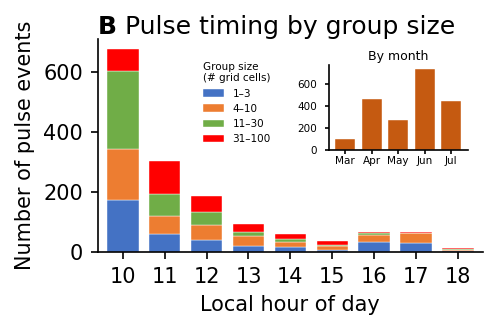

In [62]:
import numpy as np
import matplotlib.pyplot as plt

# ── settings ─────────────────────────────────────────────────────────────
HOUR_MIN   = 10
HOUR_MAX   = 18
BAR_WIDTH  = 0.75

MONTHS       = [3, 4, 5, 6, 7]
MONTH_LABELS = ["Mar", "Apr", "May", "Jun", "Jul"]

fig_b, ax_timing = plt.subplots(figsize=(3.42, 2.3), dpi=150)

# ------------------------------------------------------------------
# MAIN PANEL: hourly timing, stacked by group size
# ------------------------------------------------------------------
stacked = (
    pulse_groups.groupby(["_hour", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SIZE_LABELS, fill_value=0)
)

# Ensure all hours are present
stacked = stacked.reindex(range(HOUR_MIN, HOUR_MAX + 1), fill_value=0)

bottom = np.zeros(len(stacked))

for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = stacked[label].values
    ax_timing.bar(
        stacked.index,
        vals,
        bottom=bottom,
        width=BAR_WIDTH,
        color=color,
        label=label,
        edgecolor="white",
        linewidth=0.2,
    )
    bottom += vals

# Main axis formatting
ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(HOUR_MIN - 0.6, HOUR_MAX + 0.6)
ax_timing.set_xticks(range(HOUR_MIN, HOUR_MAX + 1))
ax_timing.spines[["top", "right"]].set_visible(False)

# Put legend away from inset
ax_timing.legend(
    title="Group size\n(# grid cells)",
    title_fontsize=5,
    fontsize=5,
    loc="center left",
    bbox_to_anchor=(0.25, 0.7),
    frameon=False,
)

ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

# ------------------------------------------------------------------
# INSET: monthly counts
# ------------------------------------------------------------------
monthly_counts = (
    pulse_groups.groupby("_month")
    .size()
    .reindex(MONTHS, fill_value=0)
)

# [x0, y0, width, height] in axis fraction coordinates
ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])

ax_month.bar(
    np.arange(len(MONTHS)),
    monthly_counts.values,
    color=COLOR_PULSE,
    edgecolor="white",
    linewidth=0.2,
    width=0.75,
)

ax_month.set_xticks(np.arange(len(MONTHS)))
ax_month.set_xticklabels(MONTH_LABELS)
ax_month.set_title("By month", fontsize=6, pad=2)

ax_month.tick_params(axis="x", labelsize=5, pad=1, length=2)
ax_month.tick_params(axis="y", labelsize=5, length=2)

ax_month.spines[["top", "right"]].set_visible(False)

# Optional: keep inset clean
ax_month.set_ylabel("")
ax_month.set_xlabel("")

plt.tight_layout()
plt.show()

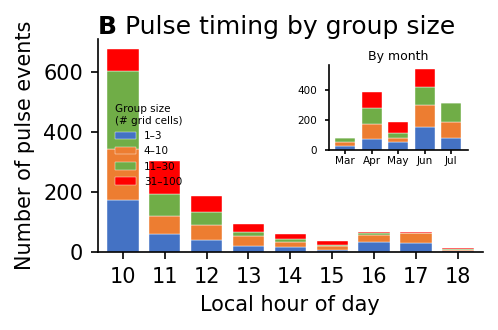

In [63]:
import numpy as np
import matplotlib.pyplot as plt

# ── settings ─────────────────────────────────────────────────────────────
HOUR_MIN   = 10
HOUR_MAX   = 18
BAR_WIDTH  = 0.75

MONTHS       = [3, 4, 5, 6, 7]
MONTH_LABELS = ["Mar", "Apr", "May", "Jun", "Jul"]

fig_b, ax_timing = plt.subplots(figsize=(3.42, 2.3), dpi=150)

# ------------------------------------------------------------------
# MAIN PANEL: hourly timing, stacked by group size
# ------------------------------------------------------------------
hourly_stacked = (
    pulse_groups.groupby(["_hour", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SIZE_LABELS, fill_value=0)
)

hourly_stacked = hourly_stacked.reindex(range(HOUR_MIN, HOUR_MAX + 1), fill_value=0)

bottom = np.zeros(len(hourly_stacked))

for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = hourly_stacked[label].values
    ax_timing.bar(
        hourly_stacked.index,
        vals,
        bottom=bottom,
        width=BAR_WIDTH,
        color=color,
        label=label,
        edgecolor="white",
        linewidth=0.2,
    )
    bottom += vals

# Main axis formatting
ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(HOUR_MIN - 0.6, HOUR_MAX + 0.6)
ax_timing.set_xticks(range(HOUR_MIN, HOUR_MAX + 1))
ax_timing.spines[["top", "right"]].set_visible(False)

# Legend in middle-left
ax_timing.legend(
    title="Group size\n(# grid cells)",
    title_fontsize=5,
    fontsize=5,
    loc="center left",
    bbox_to_anchor=(0.02, 0.50),
    frameon=False,
)

ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

# ------------------------------------------------------------------
# INSET: monthly stacked counts by group size
# ------------------------------------------------------------------
monthly_stacked = (
    pulse_groups.groupby(["_month", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=MONTHS, columns=SIZE_LABELS, fill_value=0)
)

# [left, bottom, width, height] in axes fraction
ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])

bottom = np.zeros(len(monthly_stacked))

for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = monthly_stacked[label].values
    ax_month.bar(
        np.arange(len(MONTHS)),
        vals,
        bottom=bottom,
        color=color,
        edgecolor="white",
        linewidth=0.2,
        width=0.75,
    )
    bottom += vals

ax_month.set_xticks(np.arange(len(MONTHS)))
ax_month.set_xticklabels(MONTH_LABELS, fontsize=5)
ax_month.tick_params(axis="y", labelsize=5, length=2)
ax_month.tick_params(axis="x", length=2, pad=1)

ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1529514/2506455909.py:96: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_cat        = mcm.get_cmap("tab20", min(n_groups, 20))


Setup complete.
  Pulse-start rows:         2,009
  Pulse groups:             777
  Median group size (cells): 1
  Max group size (cells):    75
  Background NO2 obs:        2,587,507


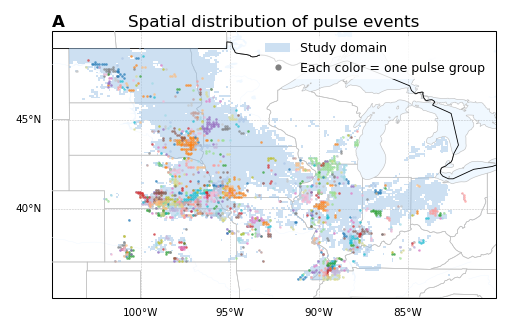

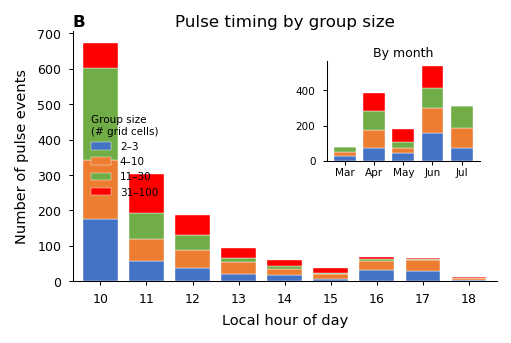

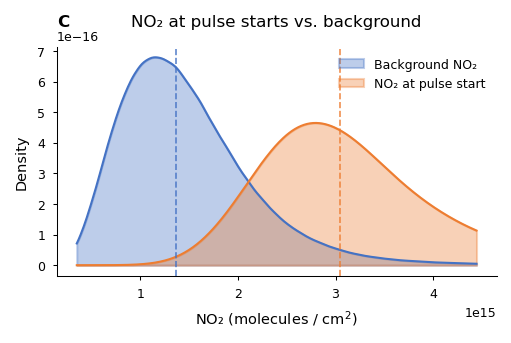

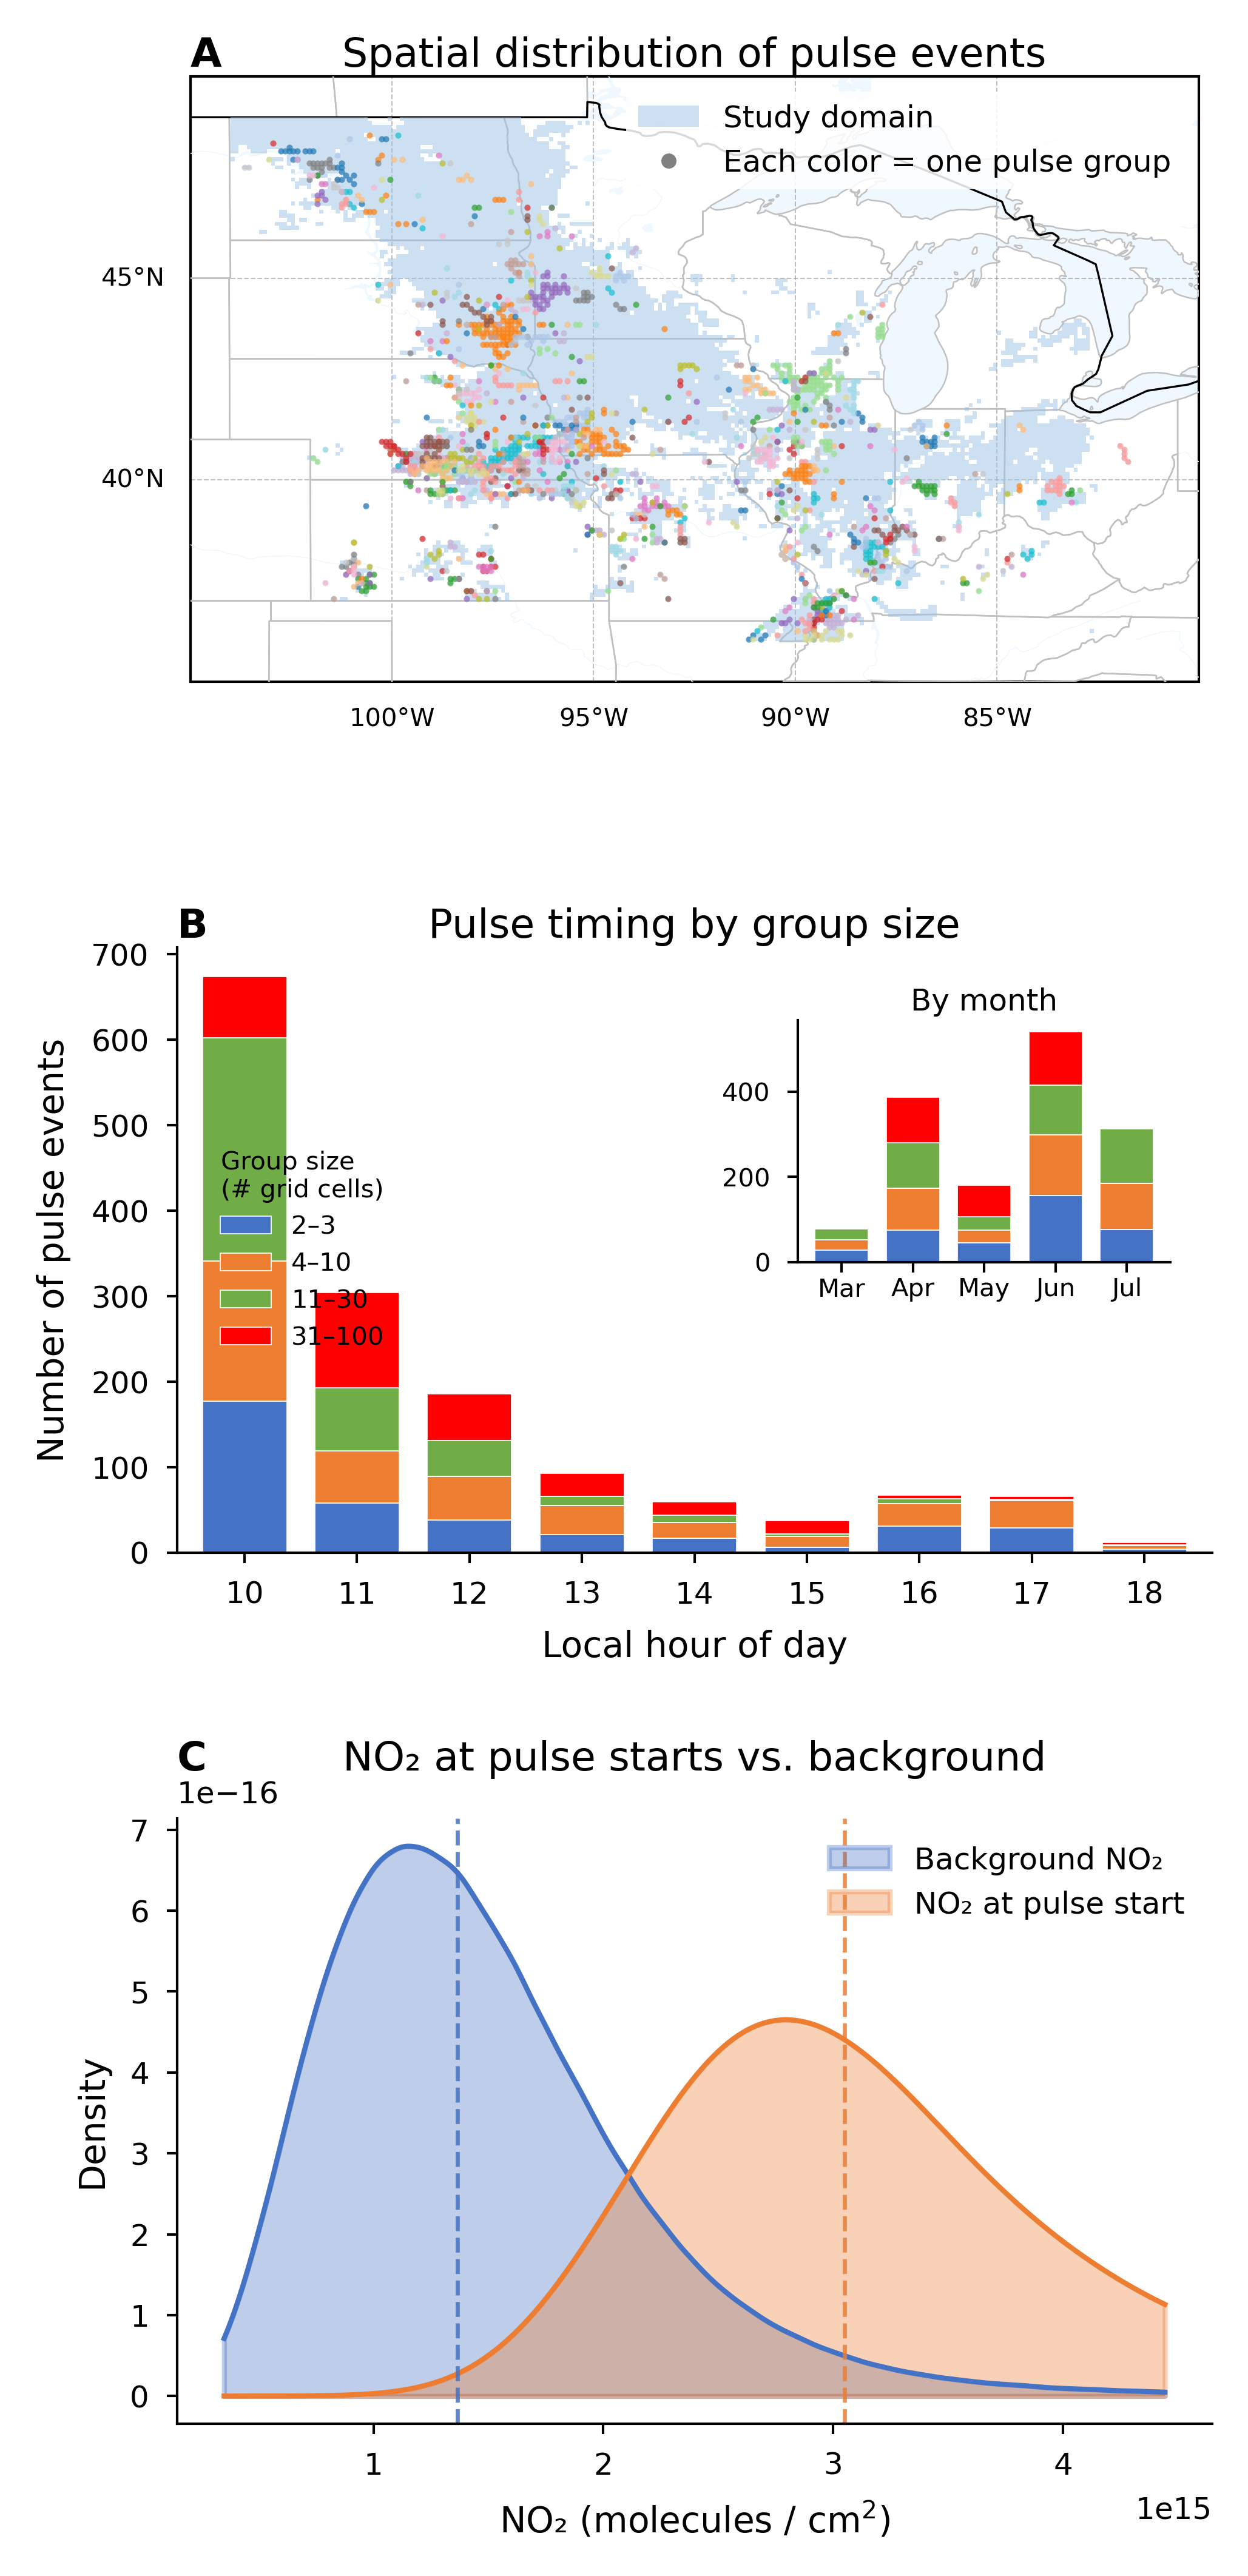

Saved: pulse_3panel_PNAS.pdf / .png


In [64]:
# =============================================================================
# Pulse Event Figure — Individual Panels + Final Assembly
# =============================================================================
# Run CELL 1 (Setup) first, then tune each panel cell independently,
# then run CELL 5 (Assembly) to produce the final PNAS figure.
# =============================================================================


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 1 — SETUP (run once before any panel cell)                       ║
# ╚═════════════════════════════════════════════════════════════════════════╝

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as mcm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.collections import PatchCollection
from scipy.stats import gaussian_kde
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ── PNAS single-column style ─────────────────────────────────────────────
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    7,
    "axes.titlesize":    8,
    "xtick.labelsize":   6,
    "ytick.labelsize":   6,
    "legend.fontsize":   6,
    "lines.linewidth":   0.8,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  2,
    "ytick.major.size":  2,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
    "svg.fonttype":      "none",
    "savefig.dpi":       600,
})

# ── Colours ──────────────────────────────────────────────────────────────
COLOR_DOMAIN = "#9DC3E6"   # light blue  — study domain grid cells
COLOR_BG     = "#4472C4"   # blue        — background NO2 KDE
COLOR_START  = "#ED7D31"   # orange      — pulse-start NO2 KDE

# Group-size bin colours — used in Panel B and map legend
SIZE_BINS   = [2, 4, 11, 31, 101]
SIZE_LABELS = ["2–3", "4–10", "11–30", "31–100"]
SIZE_COLORS = ["#4472C4", "#ED7D31", "#70AD47", "#FF0000"]

COLOR_MONTH_BAR = "#70AD47"   # monthly inset bars

# ── Data prep ────────────────────────────────────────────────────────────

# Pulse-start rows from df
pulse_df = df[df["pulse_start"] == True].copy()
pulse_df["datetime_local"] = pd.to_datetime(pulse_df["datetime_local"])
pulse_df["_hour"]  = pulse_df["datetime_local"].dt.hour
pulse_df["_month"] = pulse_df["datetime_local"].dt.month

# All unique grid cells in the study domain
all_cells = df[["grid_lat", "grid_lon"]].drop_duplicates()

# ── Group size: number of UNIQUE GRID CELLS per group ────────────────────
# groups_df has one row per grid-cell per timestep within each group.
# Counting raw rows would overcount — we deduplicate by (group_id, lat, lon)
# first so each grid cell is counted exactly once per group.
group_sizes = (
    groups_df
    .drop_duplicates(subset=["group_id", "grid_lat", "grid_lon"])
    .groupby("group_id")
    .size()
    .reset_index(name="group_size")
)

# Group centroids: mean lat/lon of unique grid cells per group
group_centroids = (
    groups_df
    .drop_duplicates(subset=["group_id", "grid_lat", "grid_lon"])
    .groupby("group_id")[["grid_lat", "grid_lon"]]
    .mean()
    .reset_index()
    .rename(columns={"grid_lat": "centroid_lat", "grid_lon": "centroid_lon"})
    .merge(group_sizes, on="group_id")
)

# Assign each group a unique categorical colour (tab20 cycles if >20 groups)
unique_groups   = group_centroids["group_id"].values
n_groups        = len(unique_groups)
cmap_cat        = mcm.get_cmap("tab20", min(n_groups, 20))
group_color_map = {gid: cmap_cat(i % 20) for i, gid in enumerate(unique_groups)}

# All individual grid-cell rows with their group colour
groups_with_size = (
    groups_df
    .drop_duplicates(subset=["group_id", "grid_lat", "grid_lon"])
    .merge(group_sizes, on="group_id")
)
groups_with_size["_color"] = groups_with_size["group_id"].map(group_color_map)

# Timing: one row per pulse-start event (one per group), with group size & bins
groups_df_t = groups_df.copy()
groups_df_t["datetime_local"] = pd.to_datetime(groups_df_t["datetime_local"])
pulse_groups = groups_df_t[groups_df_t["pulse_start"] == True].copy()
pulse_groups["_hour"]  = pulse_groups["datetime_local"].dt.hour
pulse_groups["_month"] = pulse_groups["datetime_local"].dt.month
pulse_groups = pulse_groups.merge(group_sizes, on="group_id")
pulse_groups["size_bin"] = pd.cut(
    pulse_groups["group_size"],
    bins=SIZE_BINS,
    labels=SIZE_LABELS,
    right=False,
)

# NO2 arrays for KDE
bg_vals    = df.loc[df["pulse_start"] != True, "no2_mean"].dropna().values
start_vals = pulse_df["no2_mean"].dropna().values

# KDE x-range (computed once, reused in panel cell and assembly)
KDE_LO = np.percentile(np.concatenate([bg_vals, start_vals]), 0.5)
KDE_HI = np.percentile(np.concatenate([bg_vals, start_vals]), 99.5)
kde_x  = np.linspace(KDE_LO, KDE_HI, 400)
kde_bg    = gaussian_kde(bg_vals,    bw_method="scott")
kde_start = gaussian_kde(start_vals, bw_method="scott")

print("Setup complete.")
print(f"  Pulse-start rows:         {len(pulse_df):,}")
print(f"  Pulse groups:             {len(group_centroids):,}")
print(f"  Median group size (cells): {group_sizes['group_size'].median():.0f}")
print(f"  Max group size (cells):    {group_sizes['group_size'].max():.0f}")
print(f"  Background NO2 obs:        {len(bg_vals):,}")


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 2 — PANEL A: Map                                                 ║
# ╚═════════════════════════════════════════════════════════════════════════╝

# ── Tunable settings ─────────────────────────────────────────────────────
MAP_EXTENT     = [-105, -80, 35, 50]   # [lon_min, lon_max, lat_min, lat_max]
CELL_S         = 1.5                   # dot size for individual grid cells
CELL_ALPHA     = 0.7                   # transparency for grid cell dots
GRIDLINE_XLOCS = range(-110, -75, 5)
GRIDLINE_YLOCS = range(35, 55, 5)
# ─────────────────────────────────────────────────────────────────────────

proj   = ccrs.PlateCarree()
fig_a, ax_map = plt.subplots(
    figsize=(3.42, 2.6), dpi=150,
    subplot_kw={"projection": proj},
)
ax_map.set_extent(MAP_EXTENT, crs=proj)

ax_map.add_feature(cfeature.LAND.with_scale("50m"),
                   facecolor="white", zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),
                   facecolor="aliceblue", linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"),
                   edgecolor="aliceblue", linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"),
                   edgecolor="silver", linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"),
                   edgecolor="black", linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)

# Study domain rectangles (0.1° cells, matching your notebook style)
cell_w, cell_h = 0.1, 0.1
rects = [
    Rectangle((lon - cell_w/2, lat - cell_h/2), cell_w, cell_h)
    for lon, lat in zip(all_cells["grid_lon"], all_cells["grid_lat"])
]
pc = PatchCollection(rects, facecolor=COLOR_DOMAIN, edgecolor="none",
                     alpha=0.5, linewidth=0, zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)

# Each group's grid cells in its unique colour
for gid, grp in groups_with_size.groupby("group_id"):
    ax_map.scatter(
        grp["grid_lon"], grp["grid_lat"],
        s=CELL_S, color=grp["_color"].iloc[0],
        alpha=CELL_ALPHA, linewidths=0,
        transform=proj, zorder=8,
    )

gl = ax_map.gridlines(
    draw_labels=True, linewidth=0.25, color="gray",
    alpha=0.5, linestyle="--",
    xlocs=GRIDLINE_XLOCS, ylocs=GRIDLINE_YLOCS,
)
gl.top_labels   = False
gl.right_labels = False
gl.xlabel_style = {"size": 5}
gl.ylabel_style = {"size": 5}

legend_els = [
    Patch(facecolor=COLOR_DOMAIN, edgecolor="none", alpha=0.5,
          label="Study domain"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor="gray",
           markersize=4, label="Each color = one pulse group"),
]
ax_map.legend(handles=legend_els, loc="upper right",
              frameon=True, framealpha=0.85, edgecolor="none", fontsize=6)
ax_map.set_title("A", loc="left", fontweight="bold", pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

plt.tight_layout()
plt.show()


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 3 — PANEL B: Pulse timing (stacked by group size + monthly inset)║
# ╚═════════════════════════════════════════════════════════════════════════╝

# ── Tunable settings ─────────────────────────────────────────────────────
HOUR_MIN     = 10
HOUR_MAX     = 18
BAR_WIDTH    = 0.75
MONTHS       = [3, 4, 5, 6, 7]
MONTH_LABELS = ["Mar", "Apr", "May", "Jun", "Jul"]
# ─────────────────────────────────────────────────────────────────────────

fig_b, ax_timing = plt.subplots(figsize=(3.42, 2.3), dpi=150)

# Stacked hourly bars by group size bin
hourly_stacked = (
    pulse_groups
    .groupby(["_hour", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SIZE_LABELS, fill_value=0)
    .reindex(range(HOUR_MIN, HOUR_MAX + 1), fill_value=0)
)

bottom = np.zeros(len(hourly_stacked))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = hourly_stacked[label].values
    ax_timing.bar(
        hourly_stacked.index, vals,
        bottom=bottom, width=BAR_WIDTH,
        color=color, label=label,
        edgecolor="white", linewidth=0.2,
    )
    bottom += vals

ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(HOUR_MIN - 0.6, HOUR_MAX + 0.6)
ax_timing.set_xticks(range(HOUR_MIN, HOUR_MAX + 1))
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.legend(
    title="Group size\n(# grid cells)",
    title_fontsize=5, fontsize=5,
    loc="center left",
    bbox_to_anchor=(0.02, 0.50),
    frameon=False,
)
ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

# Monthly inset (stacked by group size, filtered to active months)
monthly_stacked = (
    pulse_groups
    .groupby(["_month", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=MONTHS, columns=SIZE_LABELS, fill_value=0)
)

ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])
bottom_m = np.zeros(len(MONTHS))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = monthly_stacked[label].values
    ax_month.bar(
        np.arange(len(MONTHS)), vals,
        bottom=bottom_m, color=color,
        edgecolor="white", linewidth=0.2, width=0.75,
    )
    bottom_m += vals

ax_month.set_xticks(np.arange(len(MONTHS)))
ax_month.set_xticklabels(MONTH_LABELS, fontsize=5)
ax_month.tick_params(axis="y", labelsize=5, length=2)
ax_month.tick_params(axis="x", length=2, pad=1)
ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 4 — PANEL C: NO2 KDE                                             ║
# ╚═════════════════════════════════════════════════════════════════════════╝

# ── Tunable settings ─────────────────────────────────────────────────────
NO2_UNITS = "molecules / cm$^2$"
# ─────────────────────────────────────────────────────────────────────────

fig_c, ax_kde = plt.subplots(figsize=(3.42, 2.3), dpi=150)

ax_kde.fill_between(kde_x, kde_bg(kde_x),    alpha=0.35, color=COLOR_BG,
                    label="Background NO₂")
ax_kde.fill_between(kde_x, kde_start(kde_x), alpha=0.35, color=COLOR_START,
                    label="NO₂ at pulse start")
ax_kde.plot(kde_x, kde_bg(kde_x),    color=COLOR_BG,    linewidth=1.0)
ax_kde.plot(kde_x, kde_start(kde_x), color=COLOR_START, linewidth=1.0)

for vals, color in [(bg_vals, COLOR_BG), (start_vals, COLOR_START)]:
    ax_kde.axvline(np.median(vals), color=color,
                   linewidth=0.8, linestyle="--", alpha=0.85)

ax_kde.set_xlabel(f"NO₂ ({NO2_UNITS})")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C", loc="left", fontweight="bold", pad=2)
ax_kde.set_title("NO₂ at pulse starts vs. background", pad=2)

plt.tight_layout()
plt.show()


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 5 — ASSEMBLY: combine all panels into the final PNAS figure      ║
# ╚═════════════════════════════════════════════════════════════════════════╝
# Run after you are happy with all three panels individually.
# Uses the same tunable variables set in the panel cells above.

cm_inch = 1 / 2.54
proj = ccrs.PlateCarree()
fig  = plt.figure(figsize=(8.7 * cm_inch, 18 * cm_inch), dpi=600)
gs   = gridspec.GridSpec(
    3, 1, figure=fig,
    hspace=0.44,
    top=0.97, bottom=0.06, left=0.14, right=0.97,
)

# ── Panel A ──────────────────────────────────────────────────────────────
ax_map = fig.add_subplot(gs[0], projection=proj)
ax_map.set_extent(MAP_EXTENT, crs=proj)
ax_map.add_feature(cfeature.LAND.with_scale("50m"),    facecolor="white",     zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),   facecolor="aliceblue", linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"),  edgecolor="aliceblue", linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"),  edgecolor="silver",    linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black",     linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)

rects = [
    Rectangle((lon - cell_w/2, lat - cell_h/2), cell_w, cell_h)
    for lon, lat in zip(all_cells["grid_lon"], all_cells["grid_lat"])
]
pc = PatchCollection(rects, facecolor=COLOR_DOMAIN, edgecolor="none",
                     alpha=0.5, linewidth=0, zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)

for gid, grp in groups_with_size.groupby("group_id"):
    ax_map.scatter(grp["grid_lon"], grp["grid_lat"],
                   s=CELL_S, color=grp["_color"].iloc[0],
                   alpha=CELL_ALPHA, linewidths=0,
                   transform=proj, zorder=8)

gl = ax_map.gridlines(draw_labels=True, linewidth=0.25, color="gray",
                      alpha=0.5, linestyle="--",
                      xlocs=GRIDLINE_XLOCS, ylocs=GRIDLINE_YLOCS)
gl.top_labels = False; gl.right_labels = False
gl.xlabel_style = {"size": 5}; gl.ylabel_style = {"size": 5}
legend_els = [
    Patch(facecolor=COLOR_DOMAIN, edgecolor="none", alpha=0.5, label="Study domain"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor="gray",
           markersize=4, label="Each color = one pulse group"),
]
ax_map.legend(handles=legend_els, loc="upper right",
              frameon=True, framealpha=0.85, edgecolor="none", fontsize=6)
ax_map.set_title("A", loc="left", fontweight="bold", pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

# ── Panel B ──────────────────────────────────────────────────────────────
ax_timing = fig.add_subplot(gs[1])
bottom = np.zeros(len(hourly_stacked))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = hourly_stacked[label].values
    ax_timing.bar(hourly_stacked.index, vals, bottom=bottom, width=BAR_WIDTH,
                  color=color, label=label, edgecolor="white", linewidth=0.2)
    bottom += vals
ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(HOUR_MIN - 0.6, HOUR_MAX + 0.6)
ax_timing.set_xticks(range(HOUR_MIN, HOUR_MAX + 1))
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.legend(title="Group size\n(# grid cells)", title_fontsize=5, fontsize=5,
                 loc="center left", bbox_to_anchor=(0.02, 0.50), frameon=False)
ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])
bottom_m = np.zeros(len(MONTHS))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = monthly_stacked[label].values
    ax_month.bar(np.arange(len(MONTHS)), vals, bottom=bottom_m,
                 color=color, edgecolor="white", linewidth=0.2, width=0.75)
    bottom_m += vals
ax_month.set_xticks(np.arange(len(MONTHS)))
ax_month.set_xticklabels(MONTH_LABELS, fontsize=5)
ax_month.tick_params(axis="y", labelsize=5, length=2)
ax_month.tick_params(axis="x", length=2, pad=1)
ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.spines[["top", "right"]].set_visible(False)

# ── Panel C ──────────────────────────────────────────────────────────────
ax_kde = fig.add_subplot(gs[2])
ax_kde.fill_between(kde_x, kde_bg(kde_x),    alpha=0.35, color=COLOR_BG,    label="Background NO₂")
ax_kde.fill_between(kde_x, kde_start(kde_x), alpha=0.35, color=COLOR_START, label="NO₂ at pulse start")
ax_kde.plot(kde_x, kde_bg(kde_x),    color=COLOR_BG,    linewidth=1.0)
ax_kde.plot(kde_x, kde_start(kde_x), color=COLOR_START, linewidth=1.0)
for vals, color in [(bg_vals, COLOR_BG), (start_vals, COLOR_START)]:
    ax_kde.axvline(np.median(vals), color=color,
                   linewidth=0.8, linestyle="--", alpha=0.85)
ax_kde.set_xlabel(f"NO₂ ({NO2_UNITS})")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C", loc="left", fontweight="bold", pad=2)
ax_kde.set_title("NO₂ at pulse starts vs. background", pad=2)

# ── Save ─────────────────────────────────────────────────────────────────
fig.savefig("pulse_3panel_PNAS.pdf", bbox_inches="tight")
fig.savefig("pulse_3panel_PNAS.png", bbox_inches="tight")
plt.show()
print("Saved: pulse_3panel_PNAS.pdf / .png")

/tmp/ipykernel_1529514/604858326.py:96: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_cat        = mcm.get_cmap("tab20", min(n_groups, 20))


Setup complete.
  Pulse-start rows:         2,009
  Pulse groups:             777
  Median group size (cells): 1
  Max group size (cells):    75
  Background NO2 obs:        2,587,507


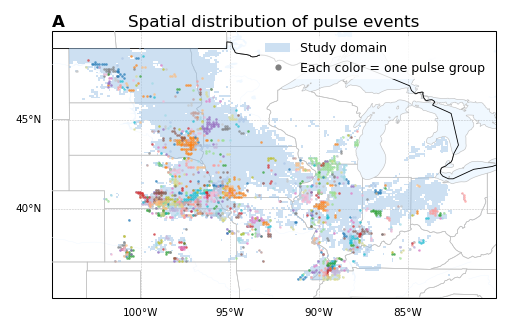

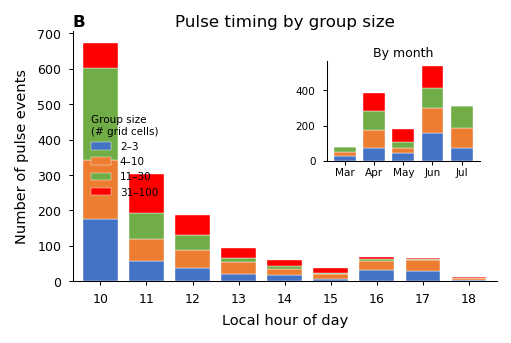

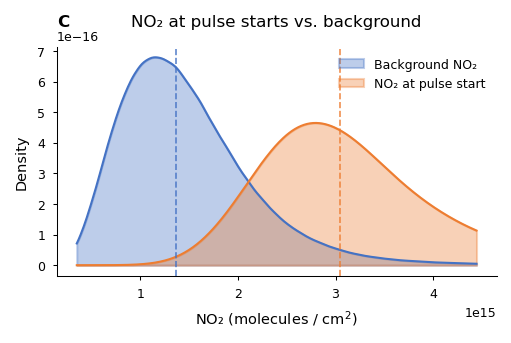

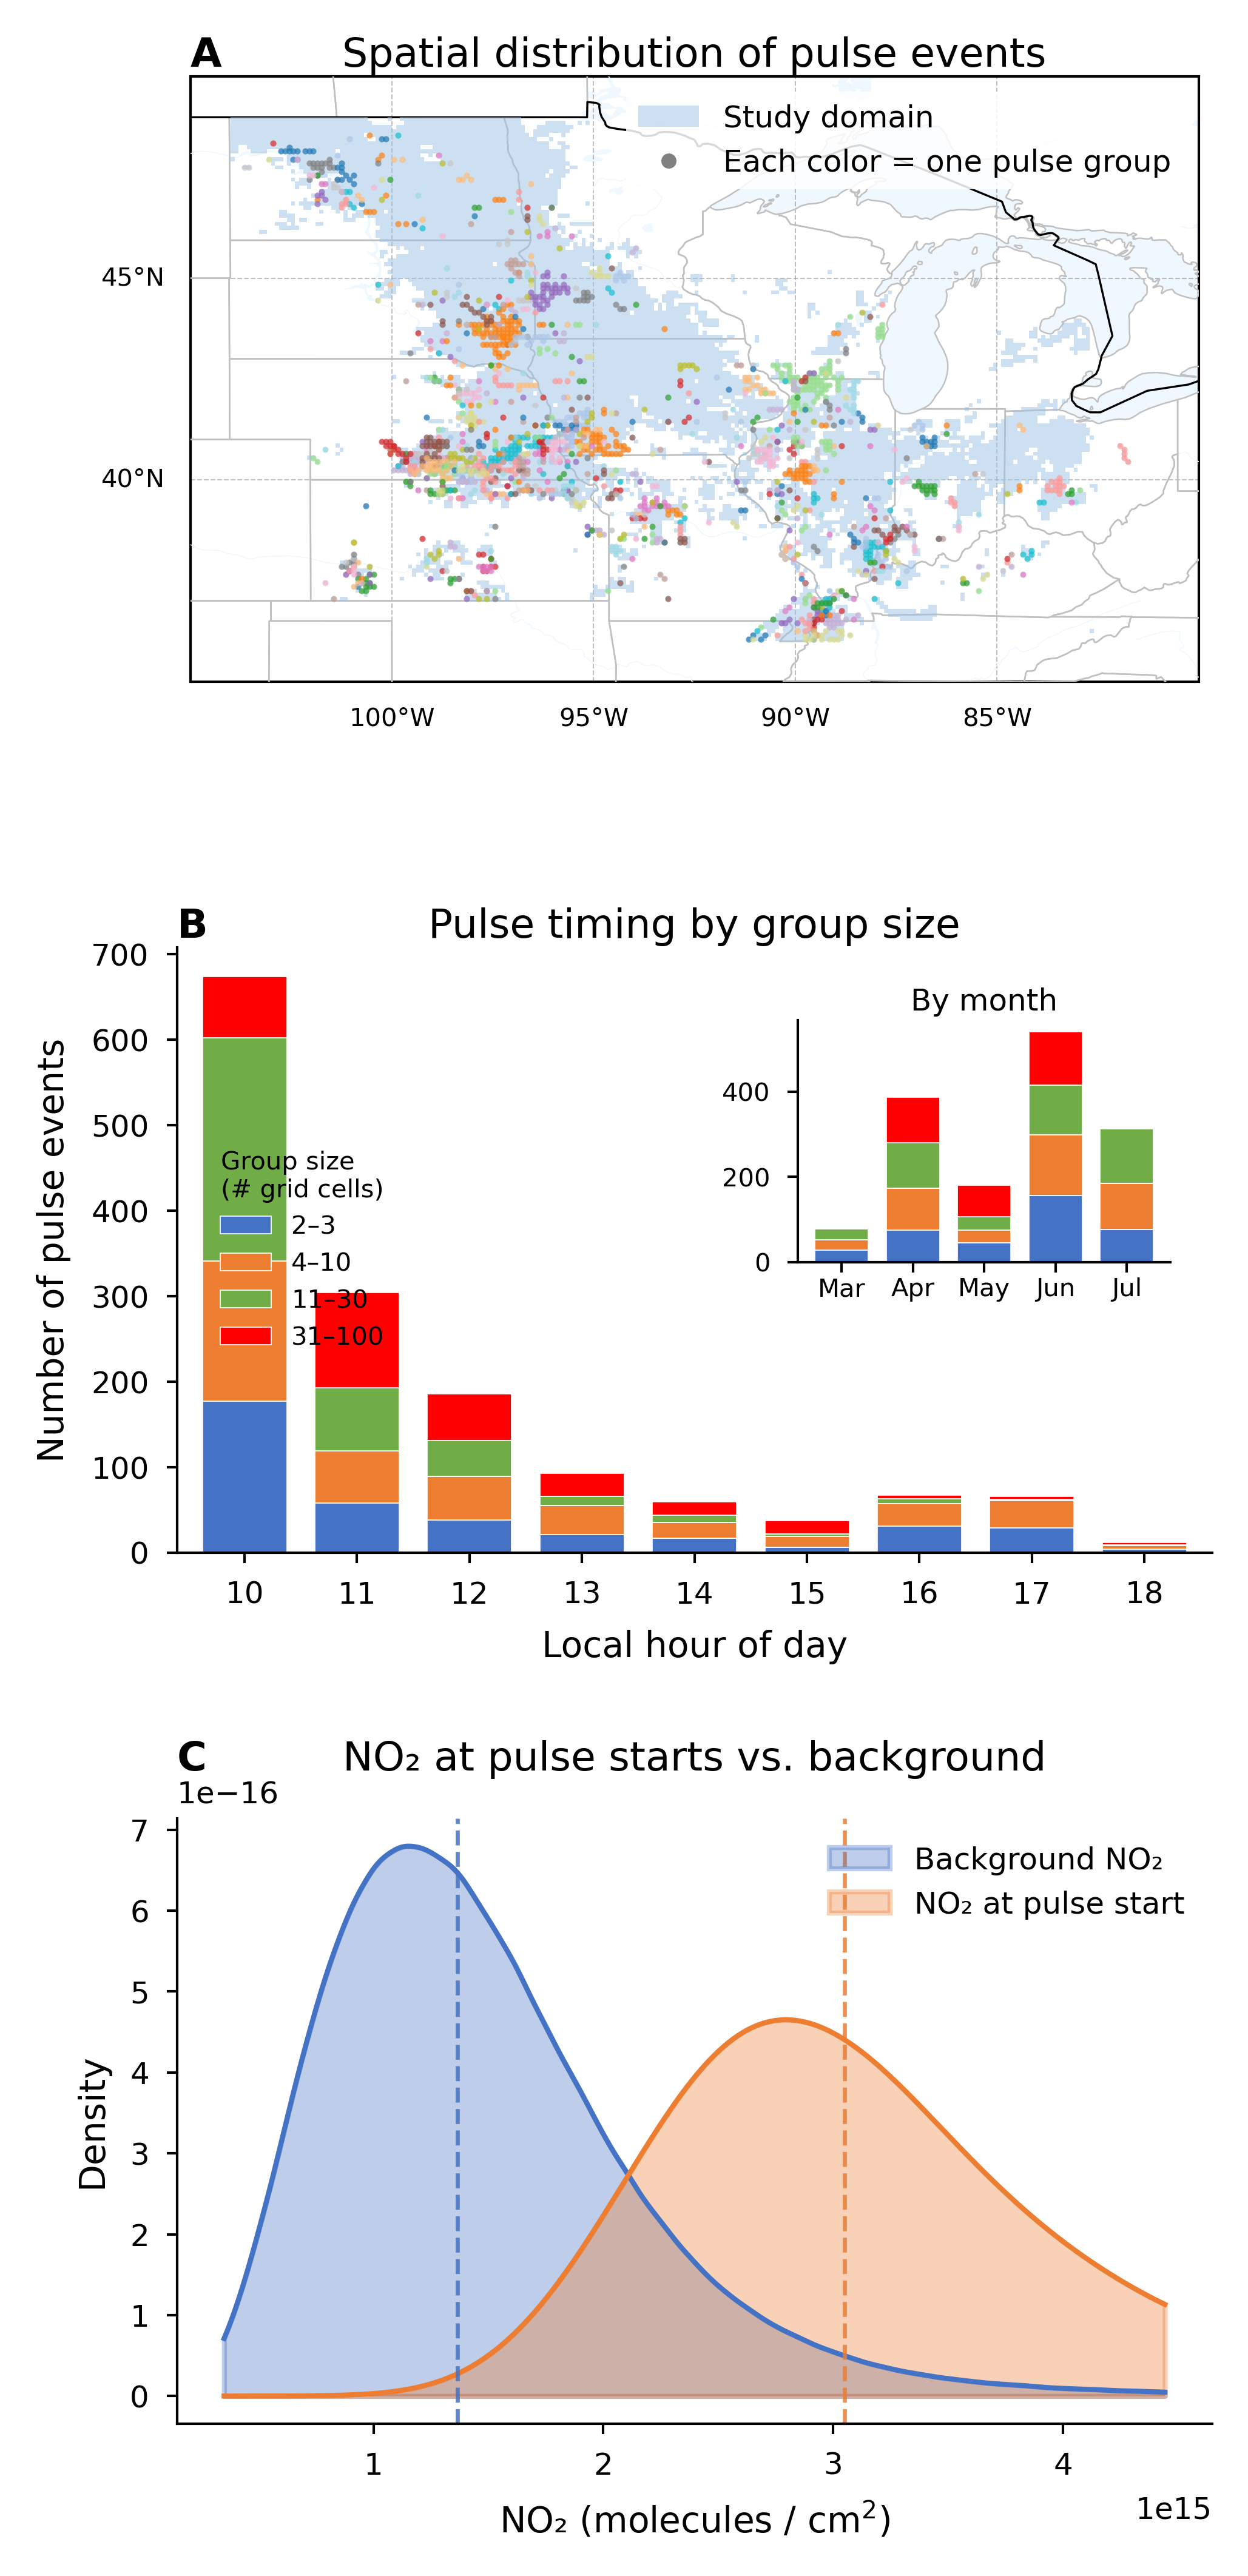

Saved: pulse_3panel_PNAS.pdf / .png


In [65]:
# =============================================================================
# Pulse Event Figure — Individual Panels + Final Assembly
# =============================================================================
# Run CELL 1 (Setup) first, then tune each panel cell independently,
# then run CELL 5 (Assembly) to produce the final PNAS figure.
# =============================================================================


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 1 — SETUP (run once before any panel cell)                       ║
# ╚═════════════════════════════════════════════════════════════════════════╝

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as mcm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.collections import PatchCollection
from scipy.stats import gaussian_kde
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ── PNAS single-column style ─────────────────────────────────────────────
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    7,
    "axes.titlesize":    8,
    "xtick.labelsize":   6,
    "ytick.labelsize":   6,
    "legend.fontsize":   6,
    "lines.linewidth":   0.8,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  2,
    "ytick.major.size":  2,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
    "svg.fonttype":      "none",
    "savefig.dpi":       600,
})

# ── Colours ──────────────────────────────────────────────────────────────
COLOR_DOMAIN = "#9DC3E6"   # light blue  — study domain grid cells
COLOR_BG     = "#4472C4"   # blue        — background NO2 KDE
COLOR_START  = "#ED7D31"   # orange      — pulse-start NO2 KDE

# Group-size bin colours — used in Panel B and map legend
SIZE_BINS   = [2, 4, 11, 31, 101]
SIZE_LABELS = ["2–3", "4–10", "11–30", "31–100"]
SIZE_COLORS = ["#4472C4", "#ED7D31", "#70AD47", "#FF0000"]

COLOR_MONTH_BAR = "#70AD47"   # monthly inset bars

# ── Data prep ────────────────────────────────────────────────────────────

# Pulse-start rows from df
pulse_df = df[df["pulse_start"] == True].copy()
pulse_df["datetime_local"] = pd.to_datetime(pulse_df["datetime_local"])
pulse_df["_hour"]  = pulse_df["datetime_local"].dt.hour
pulse_df["_month"] = pulse_df["datetime_local"].dt.month

# All unique grid cells in the study domain
all_cells = df[["grid_lat", "grid_lon"]].drop_duplicates()

# ── Group size: number of UNIQUE GRID CELLS per group ────────────────────
# groups_df has one row per grid-cell per timestep within each group.
# Counting raw rows would overcount — we deduplicate by (group_id, lat, lon)
# first so each grid cell is counted exactly once per group.
group_sizes = (
    groups_df
    .drop_duplicates(subset=["group_id", "grid_lat", "grid_lon"])
    .groupby("group_id")
    .size()
    .reset_index(name="group_size")
)

# Group centroids: mean lat/lon of unique grid cells per group
group_centroids = (
    groups_df
    .drop_duplicates(subset=["group_id", "grid_lat", "grid_lon"])
    .groupby("group_id")[["grid_lat", "grid_lon"]]
    .mean()
    .reset_index()
    .rename(columns={"grid_lat": "centroid_lat", "grid_lon": "centroid_lon"})
    .merge(group_sizes, on="group_id")
)

# Assign each group a unique categorical colour (tab20 cycles if >20 groups)
unique_groups   = group_centroids["group_id"].values
n_groups        = len(unique_groups)
cmap_cat        = mcm.get_cmap("tab20", min(n_groups, 20))
group_color_map = {gid: cmap_cat(i % 20) for i, gid in enumerate(unique_groups)}

# All individual grid-cell rows with their group colour
groups_with_size = (
    groups_df
    .drop_duplicates(subset=["group_id", "grid_lat", "grid_lon"])
    .merge(group_sizes, on="group_id")
)
groups_with_size["_color"] = groups_with_size["group_id"].map(group_color_map)

# Timing: one row per pulse-start event (one per group), with group size & bins
groups_df_t = groups_df.copy()
groups_df_t["datetime_local"] = pd.to_datetime(groups_df_t["datetime_local"])
pulse_groups = groups_df_t[groups_df_t["pulse_start"] == True].copy()
pulse_groups["_hour"]  = pulse_groups["datetime_local"].dt.hour
pulse_groups["_month"] = pulse_groups["datetime_local"].dt.month
pulse_groups = pulse_groups.merge(group_sizes, on="group_id")
pulse_groups["size_bin"] = pd.cut(
    pulse_groups["group_size"],
    bins=SIZE_BINS,
    labels=SIZE_LABELS,
    right=False,
)

# NO2 arrays for KDE
bg_vals    = df.loc[df["pulse_start"] != True, "no2_mean"].dropna().values
start_vals = pulse_df["no2_mean"].dropna().values

# KDE x-range (computed once, reused in panel cell and assembly)
KDE_LO = np.percentile(np.concatenate([bg_vals, start_vals]), 0.5)
KDE_HI = np.percentile(np.concatenate([bg_vals, start_vals]), 99.5)
kde_x  = np.linspace(KDE_LO, KDE_HI, 400)
kde_bg    = gaussian_kde(bg_vals,    bw_method="scott")
kde_start = gaussian_kde(start_vals, bw_method="scott")

print("Setup complete.")
print(f"  Pulse-start rows:         {len(pulse_df):,}")
print(f"  Pulse groups:             {len(group_centroids):,}")
print(f"  Median group size (cells): {group_sizes['group_size'].median():.0f}")
print(f"  Max group size (cells):    {group_sizes['group_size'].max():.0f}")
print(f"  Background NO2 obs:        {len(bg_vals):,}")


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 2 — PANEL A: Map                                                 ║
# ╚═════════════════════════════════════════════════════════════════════════╝

# ── Tunable settings ─────────────────────────────────────────────────────
MAP_EXTENT     = [-105, -80, 35, 50]   # [lon_min, lon_max, lat_min, lat_max]
CELL_S         = 1.5                   # dot size for individual grid cells
CELL_ALPHA     = 0.7                   # transparency for grid cell dots
GRIDLINE_XLOCS = range(-110, -75, 5)
GRIDLINE_YLOCS = range(35, 55, 5)
# ─────────────────────────────────────────────────────────────────────────

proj   = ccrs.PlateCarree()
fig_a, ax_map = plt.subplots(
    figsize=(3.42, 2.6), dpi=150,
    subplot_kw={"projection": proj},
)
ax_map.set_extent(MAP_EXTENT, crs=proj)

ax_map.add_feature(cfeature.LAND.with_scale("50m"),
                   facecolor="white", zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),
                   facecolor="aliceblue", linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"),
                   edgecolor="aliceblue", linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"),
                   edgecolor="silver", linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"),
                   edgecolor="black", linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)

# Study domain rectangles (0.1° cells, matching your notebook style)
cell_w, cell_h = 0.1, 0.1
rects = [
    Rectangle((lon - cell_w/2, lat - cell_h/2), cell_w, cell_h)
    for lon, lat in zip(all_cells["grid_lon"], all_cells["grid_lat"])
]
pc = PatchCollection(rects, facecolor=COLOR_DOMAIN, edgecolor="none",
                     alpha=0.5, linewidth=0, zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)

# Each group's grid cells in its unique colour
for gid, grp in groups_with_size.groupby("group_id"):
    ax_map.scatter(
        grp["grid_lon"], grp["grid_lat"],
        s=CELL_S, color=grp["_color"].iloc[0],
        alpha=CELL_ALPHA, linewidths=0,
        transform=proj, zorder=8,
    )

gl = ax_map.gridlines(
    draw_labels=True, linewidth=0.25, color="gray",
    alpha=0.5, linestyle="--",
    xlocs=GRIDLINE_XLOCS, ylocs=GRIDLINE_YLOCS,
)
gl.top_labels   = False
gl.right_labels = False
gl.xlabel_style = {"size": 5}
gl.ylabel_style = {"size": 5}

legend_els = [
    Patch(facecolor=COLOR_DOMAIN, edgecolor="none", alpha=0.5,
          label="Study domain"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor="gray",
           markersize=4, label="Each color = one pulse group"),
]
ax_map.legend(handles=legend_els, loc="upper right",
              frameon=True, framealpha=0.85, edgecolor="none", fontsize=6)
ax_map.set_title("A", loc="left", fontweight="bold", pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

plt.tight_layout()
plt.show()


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 3 — PANEL B: Pulse timing (stacked by group size + monthly inset)║
# ╚═════════════════════════════════════════════════════════════════════════╝

# ── Tunable settings ─────────────────────────────────────────────────────
HOUR_MIN     = 10
HOUR_MAX     = 18
BAR_WIDTH    = 0.75
MONTHS       = [3, 4, 5, 6, 7]
MONTH_LABELS = ["Mar", "Apr", "May", "Jun", "Jul"]
# ─────────────────────────────────────────────────────────────────────────

fig_b, ax_timing = plt.subplots(figsize=(3.42, 2.3), dpi=150)

# Stacked hourly bars by group size bin
hourly_stacked = (
    pulse_groups
    .groupby(["_hour", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SIZE_LABELS, fill_value=0)
    .reindex(range(HOUR_MIN, HOUR_MAX + 1), fill_value=0)
)

bottom = np.zeros(len(hourly_stacked))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = hourly_stacked[label].values
    ax_timing.bar(
        hourly_stacked.index, vals,
        bottom=bottom, width=BAR_WIDTH,
        color=color, label=label,
        edgecolor="white", linewidth=0.2,
    )
    bottom += vals

ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(HOUR_MIN - 0.6, HOUR_MAX + 0.6)
ax_timing.set_xticks(range(HOUR_MIN, HOUR_MAX + 1))
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.legend(
    title="Group size\n(# grid cells)",
    title_fontsize=5, fontsize=5,
    loc="center left",
    bbox_to_anchor=(0.02, 0.50),
    frameon=False,
)
ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

# Monthly inset (stacked by group size, filtered to active months)
monthly_stacked = (
    pulse_groups
    .groupby(["_month", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=MONTHS, columns=SIZE_LABELS, fill_value=0)
)

ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])
bottom_m = np.zeros(len(MONTHS))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = monthly_stacked[label].values
    ax_month.bar(
        np.arange(len(MONTHS)), vals,
        bottom=bottom_m, color=color,
        edgecolor="white", linewidth=0.2, width=0.75,
    )
    bottom_m += vals

ax_month.set_xticks(np.arange(len(MONTHS)))
ax_month.set_xticklabels(MONTH_LABELS, fontsize=5)
ax_month.tick_params(axis="y", labelsize=5, length=2)
ax_month.tick_params(axis="x", length=2, pad=1)
ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 4 — PANEL C: NO2 KDE                                             ║
# ╚═════════════════════════════════════════════════════════════════════════╝

# ── Tunable settings ─────────────────────────────────────────────────────
NO2_UNITS = "molecules / cm$^2$"
# ─────────────────────────────────────────────────────────────────────────

fig_c, ax_kde = plt.subplots(figsize=(3.42, 2.3), dpi=150)

ax_kde.fill_between(kde_x, kde_bg(kde_x),    alpha=0.35, color=COLOR_BG,
                    label="Background NO₂")
ax_kde.fill_between(kde_x, kde_start(kde_x), alpha=0.35, color=COLOR_START,
                    label="NO₂ at pulse start")
ax_kde.plot(kde_x, kde_bg(kde_x),    color=COLOR_BG,    linewidth=1.0)
ax_kde.plot(kde_x, kde_start(kde_x), color=COLOR_START, linewidth=1.0)

for vals, color in [(bg_vals, COLOR_BG), (start_vals, COLOR_START)]:
    ax_kde.axvline(np.median(vals), color=color,
                   linewidth=0.8, linestyle="--", alpha=0.85)

ax_kde.set_xlabel(f"NO₂ ({NO2_UNITS})")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C", loc="left", fontweight="bold", pad=2)
ax_kde.set_title("NO₂ at pulse starts vs. background", pad=2)

plt.tight_layout()
plt.show()


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 5 — ASSEMBLY: combine all panels into the final PNAS figure      ║
# ╚═════════════════════════════════════════════════════════════════════════╝
# Run after you are happy with all three panels individually.
# Uses the same tunable variables set in the panel cells above.

cm_inch = 1 / 2.54
proj = ccrs.PlateCarree()
fig  = plt.figure(figsize=(8.7 * cm_inch, 18 * cm_inch), dpi=600)
gs   = gridspec.GridSpec(
    3, 1, figure=fig,
    hspace=0.44,
    top=0.97, bottom=0.06, left=0.14, right=0.97,
)

# ── Panel A ──────────────────────────────────────────────────────────────
ax_map = fig.add_subplot(gs[0], projection=proj)
ax_map.set_extent(MAP_EXTENT, crs=proj)
ax_map.add_feature(cfeature.LAND.with_scale("50m"),    facecolor="white",     zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),   facecolor="aliceblue", linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"),  edgecolor="aliceblue", linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"),  edgecolor="silver",    linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black",     linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)

rects = [
    Rectangle((lon - cell_w/2, lat - cell_h/2), cell_w, cell_h)
    for lon, lat in zip(all_cells["grid_lon"], all_cells["grid_lat"])
]
pc = PatchCollection(rects, facecolor=COLOR_DOMAIN, edgecolor="none",
                     alpha=0.5, linewidth=0, zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)

for gid, grp in groups_with_size.groupby("group_id"):
    ax_map.scatter(grp["grid_lon"], grp["grid_lat"],
                   s=CELL_S, color=grp["_color"].iloc[0],
                   alpha=CELL_ALPHA, linewidths=0,
                   transform=proj, zorder=8)

gl = ax_map.gridlines(draw_labels=True, linewidth=0.25, color="gray",
                      alpha=0.5, linestyle="--",
                      xlocs=GRIDLINE_XLOCS, ylocs=GRIDLINE_YLOCS)
gl.top_labels = False; gl.right_labels = False
gl.xlabel_style = {"size": 5}; gl.ylabel_style = {"size": 5}
legend_els = [
    Patch(facecolor=COLOR_DOMAIN, edgecolor="none", alpha=0.5, label="Study domain"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor="gray",
           markersize=4, label="Each color = one pulse group"),
]
ax_map.legend(handles=legend_els, loc="upper right",
              frameon=True, framealpha=0.85, edgecolor="none", fontsize=6)
ax_map.set_title("A", loc="left", fontweight="bold", pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

# ── Panel B ──────────────────────────────────────────────────────────────
ax_timing = fig.add_subplot(gs[1])
bottom = np.zeros(len(hourly_stacked))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = hourly_stacked[label].values
    ax_timing.bar(hourly_stacked.index, vals, bottom=bottom, width=BAR_WIDTH,
                  color=color, label=label, edgecolor="white", linewidth=0.2)
    bottom += vals
ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(HOUR_MIN - 0.6, HOUR_MAX + 0.6)
ax_timing.set_xticks(range(HOUR_MIN, HOUR_MAX + 1))
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.legend(title="Group size\n(# grid cells)", title_fontsize=5, fontsize=5,
                 loc="center left", bbox_to_anchor=(0.02, 0.50), frameon=False)
ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])
bottom_m = np.zeros(len(MONTHS))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = monthly_stacked[label].values
    ax_month.bar(np.arange(len(MONTHS)), vals, bottom=bottom_m,
                 color=color, edgecolor="white", linewidth=0.2, width=0.75)
    bottom_m += vals
ax_month.set_xticks(np.arange(len(MONTHS)))
ax_month.set_xticklabels(MONTH_LABELS, fontsize=5)
ax_month.tick_params(axis="y", labelsize=5, length=2)
ax_month.tick_params(axis="x", length=2, pad=1)
ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.spines[["top", "right"]].set_visible(False)

# ── Panel C ──────────────────────────────────────────────────────────────
ax_kde = fig.add_subplot(gs[2])
ax_kde.fill_between(kde_x, kde_bg(kde_x),    alpha=0.35, color=COLOR_BG,    label="Background NO₂")
ax_kde.fill_between(kde_x, kde_start(kde_x), alpha=0.35, color=COLOR_START, label="NO₂ at pulse start")
ax_kde.plot(kde_x, kde_bg(kde_x),    color=COLOR_BG,    linewidth=1.0)
ax_kde.plot(kde_x, kde_start(kde_x), color=COLOR_START, linewidth=1.0)
for vals, color in [(bg_vals, COLOR_BG), (start_vals, COLOR_START)]:
    ax_kde.axvline(np.median(vals), color=color,
                   linewidth=0.8, linestyle="--", alpha=0.85)
ax_kde.set_xlabel(f"NO₂ ({NO2_UNITS})")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C", loc="left", fontweight="bold", pad=2)
ax_kde.set_title("NO₂ at pulse starts vs. background", pad=2)

# ── Save ─────────────────────────────────────────────────────────────────
fig.savefig("pulse_3panel_PNAS.pdf", bbox_inches="tight")
fig.savefig("pulse_3panel_PNAS.png", bbox_inches="tight")
plt.show()
print("Saved: pulse_3panel_PNAS.pdf / .png")


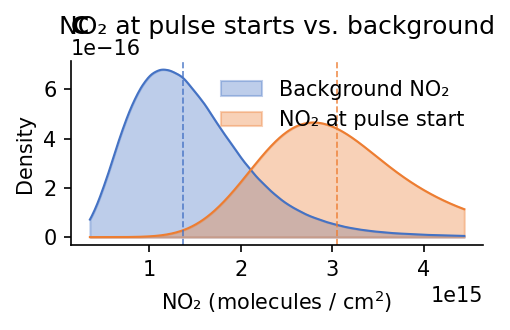

In [23]:
# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 4 — PANEL C: NO2 KDE                                             ║
# ╚═════════════════════════════════════════════════════════════════════════╝

# ── Tunable settings ─────────────────────────────────────────────────────
KDE_PERCENTILE_LO = 0.5 # lower clip percentile (removes extreme outliers)
KDE_PERCENTILE_HI = 99.5   # upper clip percentile
NO2_UNITS = "molecules / cm$^2$"   # update if your units differ

fig_c, ax_kde = plt.subplots(figsize=(3.42, 2.3), dpi=150)

lo = np.percentile(np.concatenate([bg_vals, start_vals]), KDE_PERCENTILE_LO)
hi = np.percentile(np.concatenate([bg_vals, start_vals]), KDE_PERCENTILE_HI)
x  = np.linspace(lo, hi, 400)

kde_bg = gaussian_kde(bg_vals, bw_method="scott")
kde_start = gaussian_kde(start_vals, bw_method="scott")

ax_kde.fill_between(x, kde_bg(x),    alpha=0.35, color=COLOR_BG,label="Background NO₂")
ax_kde.fill_between(x, kde_start(x), alpha=0.35, color=COLOR_START,label="NO₂ at pulse start")
ax_kde.plot(x, kde_bg(x),    color=COLOR_BG,    linewidth=1.0)
ax_kde.plot(x, kde_start(x), color=COLOR_START, linewidth=1.0)

for vals, color in [(bg_vals, COLOR_BG), (start_vals, COLOR_START)]:
    ax_kde.axvline(np.median(vals), color=color,linewidth=0.8, linestyle="--", alpha=0.85)

ax_kde.set_xlabel(f"NO₂ ({NO2_UNITS})")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C", loc="left", fontweight="bold", pad=2)
ax_kde.set_title("NO₂ at pulse starts vs. background", pad=2)

plt.tight_layout()
plt.show()

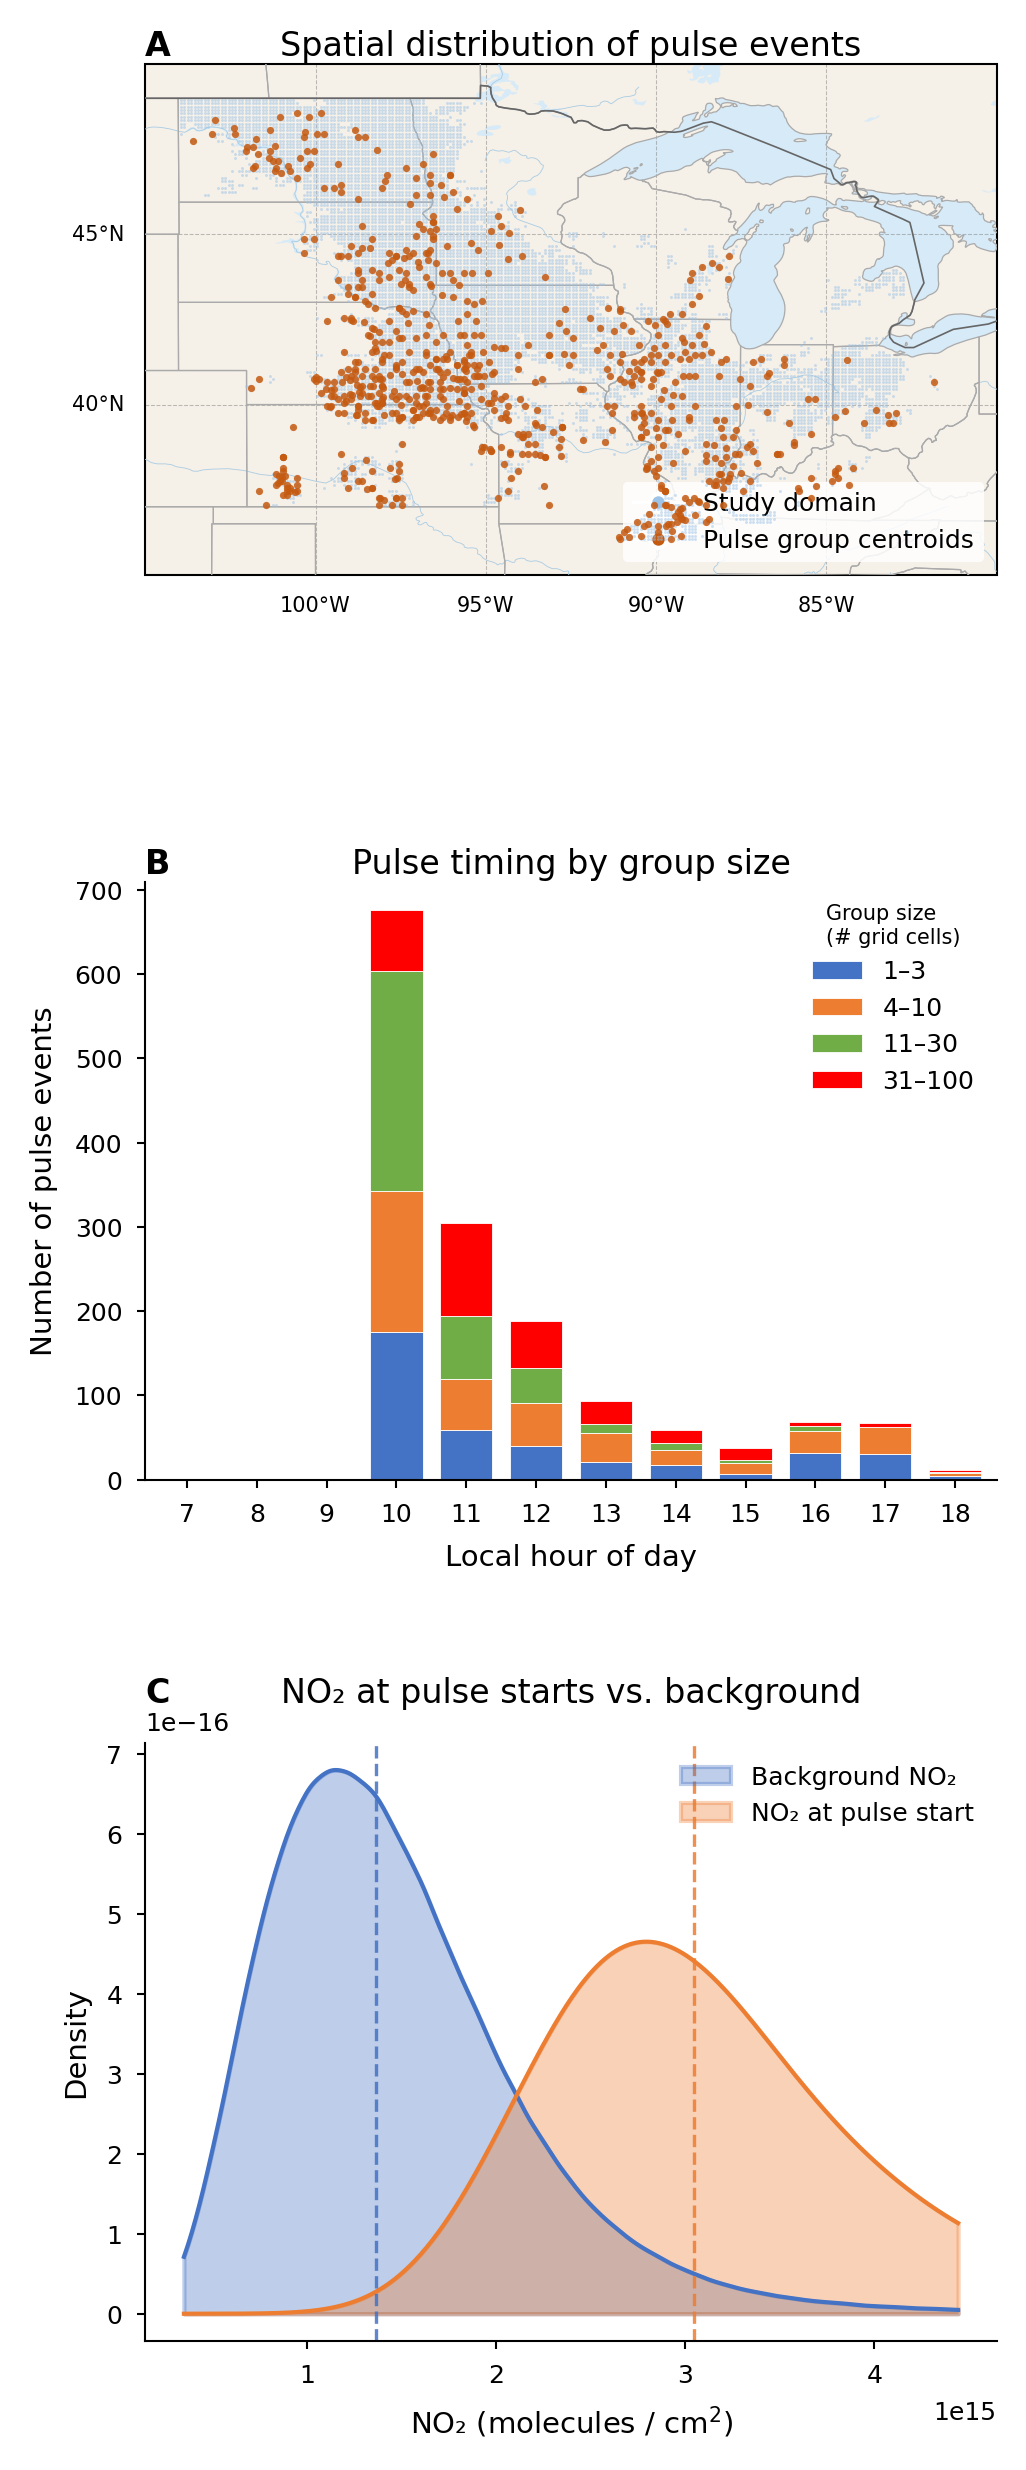

Saved: pulse_3panel_PNAS.pdf / .png


In [41]:
# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  CELL 5 — ASSEMBLY: combine all three panels into final PNAS figure    ║
# ╚═════════════════════════════════════════════════════════════════════════╝
# Run this cell last, after you are happy with each panel individually.
# It redraws all three panels using the same tunable settings from above.

proj   = ccrs.PlateCarree()
fig    = plt.figure(figsize=(3.42, 8.5), dpi=300)
gs     = gridspec.GridSpec(
    3, 1, figure=fig,
    hspace=0.44,
    top=0.97, bottom=0.06, left=0.14, right=0.97,
)

# ── Panel A ──────────────────────────────────────────────────────────────
ax_map = fig.add_subplot(gs[0], projection=proj)
ax_map.set_extent(MAP_EXTENT, crs=proj)

ax_map.add_feature(cfeature.OCEAN.with_scale("50m"),  facecolor="#D6EAF8", zorder=0)
ax_map.add_feature(cfeature.LAND.with_scale("50m"),   facecolor="#F5F0E8", zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),  facecolor="#D6EAF8", linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"), edgecolor="#A9CCE3", linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="#AAAAAA", linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"),edgecolor="#666666", linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)
ax_map.scatter(all_cells["grid_lon"], all_cells["grid_lat"],
               s=DOMAIN_S, c=COLOR_DOMAIN, alpha=DOMAIN_ALPHA,
               linewidths=0, transform=proj, zorder=7)
ax_map.scatter(group_centroids["centroid_lon"], group_centroids["centroid_lat"],
               s=CENTROID_S, c=COLOR_PULSE, alpha=CENTROID_ALPHA,
               linewidths=0, transform=proj, zorder=8)
gl = ax_map.gridlines(draw_labels=True, linewidth=0.25, color="gray",
                      alpha=0.5, linestyle="--",
                      xlocs=GRIDLINE_XLOCS, ylocs=GRIDLINE_YLOCS)
gl.top_labels = False; gl.right_labels = False
gl.xlabel_style = {"size": 5}; gl.ylabel_style = {"size": 5}
ax_map.legend(handles=legend_els, loc="lower right",
              frameon=True, framealpha=0.85, edgecolor="none")
ax_map.set_title("A", loc="left", fontweight="bold", pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

# ── Panel B ──────────────────────────────────────────────────────────────
ax_timing = fig.add_subplot(gs[1])
bottom = np.zeros(len(stacked))
for label, color in zip(SIZE_LABELS, SIZE_COLORS):
    vals = stacked[label].values
    ax_timing.bar(stacked.index, vals, bottom=bottom, width=BAR_WIDTH,
                  color=color, label=label, edgecolor="white", linewidth=0.2)
    bottom += vals
ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(HOUR_MIN - 0.6, HOUR_MAX + 0.6)
ax_timing.set_xticks(range(HOUR_MIN, HOUR_MAX + 1))
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.legend(title="Group size\n(# grid cells)", title_fontsize=5,
                 loc="upper right", frameon=False)
ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

# ── Panel C ──────────────────────────────────────────────────────────────
ax_kde = fig.add_subplot(gs[2])
ax_kde.fill_between(x, kde_bg(x),    alpha=0.35, color=COLOR_BG,    label="Background NO₂")
ax_kde.fill_between(x, kde_start(x), alpha=0.35, color=COLOR_START, label="NO₂ at pulse start")
ax_kde.plot(x, kde_bg(x),    color=COLOR_BG,    linewidth=1.0)
ax_kde.plot(x, kde_start(x), color=COLOR_START, linewidth=1.0)
for vals, color in [(bg_vals, COLOR_BG), (start_vals, COLOR_START)]:
    ax_kde.axvline(np.median(vals), color=color,
                   linewidth=0.8, linestyle="--", alpha=0.85)
ax_kde.set_xlabel(f"NO₂ ({NO2_UNITS})")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C", loc="left", fontweight="bold", pad=2)
ax_kde.set_title("NO₂ at pulse starts vs. background", pad=2)

# ── Save ─────────────────────────────────────────────────────────────────
fig.savefig("pulse_3panel_PNAS.pdf", dpi=300, bbox_inches="tight")
fig.savefig("pulse_3panel_PNAS.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pulse_3panel_PNAS.pdf / .png")


# PNAS figure 

In [26]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [31]:
#PNAS figure settings
cm = 1 /2.54

# PNAS widths-- same as text column = 8.7 cm, medium wide = 11.4 cm, full wide = 17.8 cm
fig_width = 8.7 *cm
fig_height = 18 *cm

plt.rcParams.update(plt.rcParamsDefault)

plt.rcParams.update({
    #font sizes should be 6–12 pt according to template
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "lines.linewidth":   0.8,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  2,
    "ytick.major.size":  2,

    #font embedding for pdf/eps
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    
    "svg.fonttype": "none",
    "savefig.dpi": 600,
})

colar_domain ='light_blue'
color_pulse ='orange'
color_bg = 'blue'
color_start = 'orange'

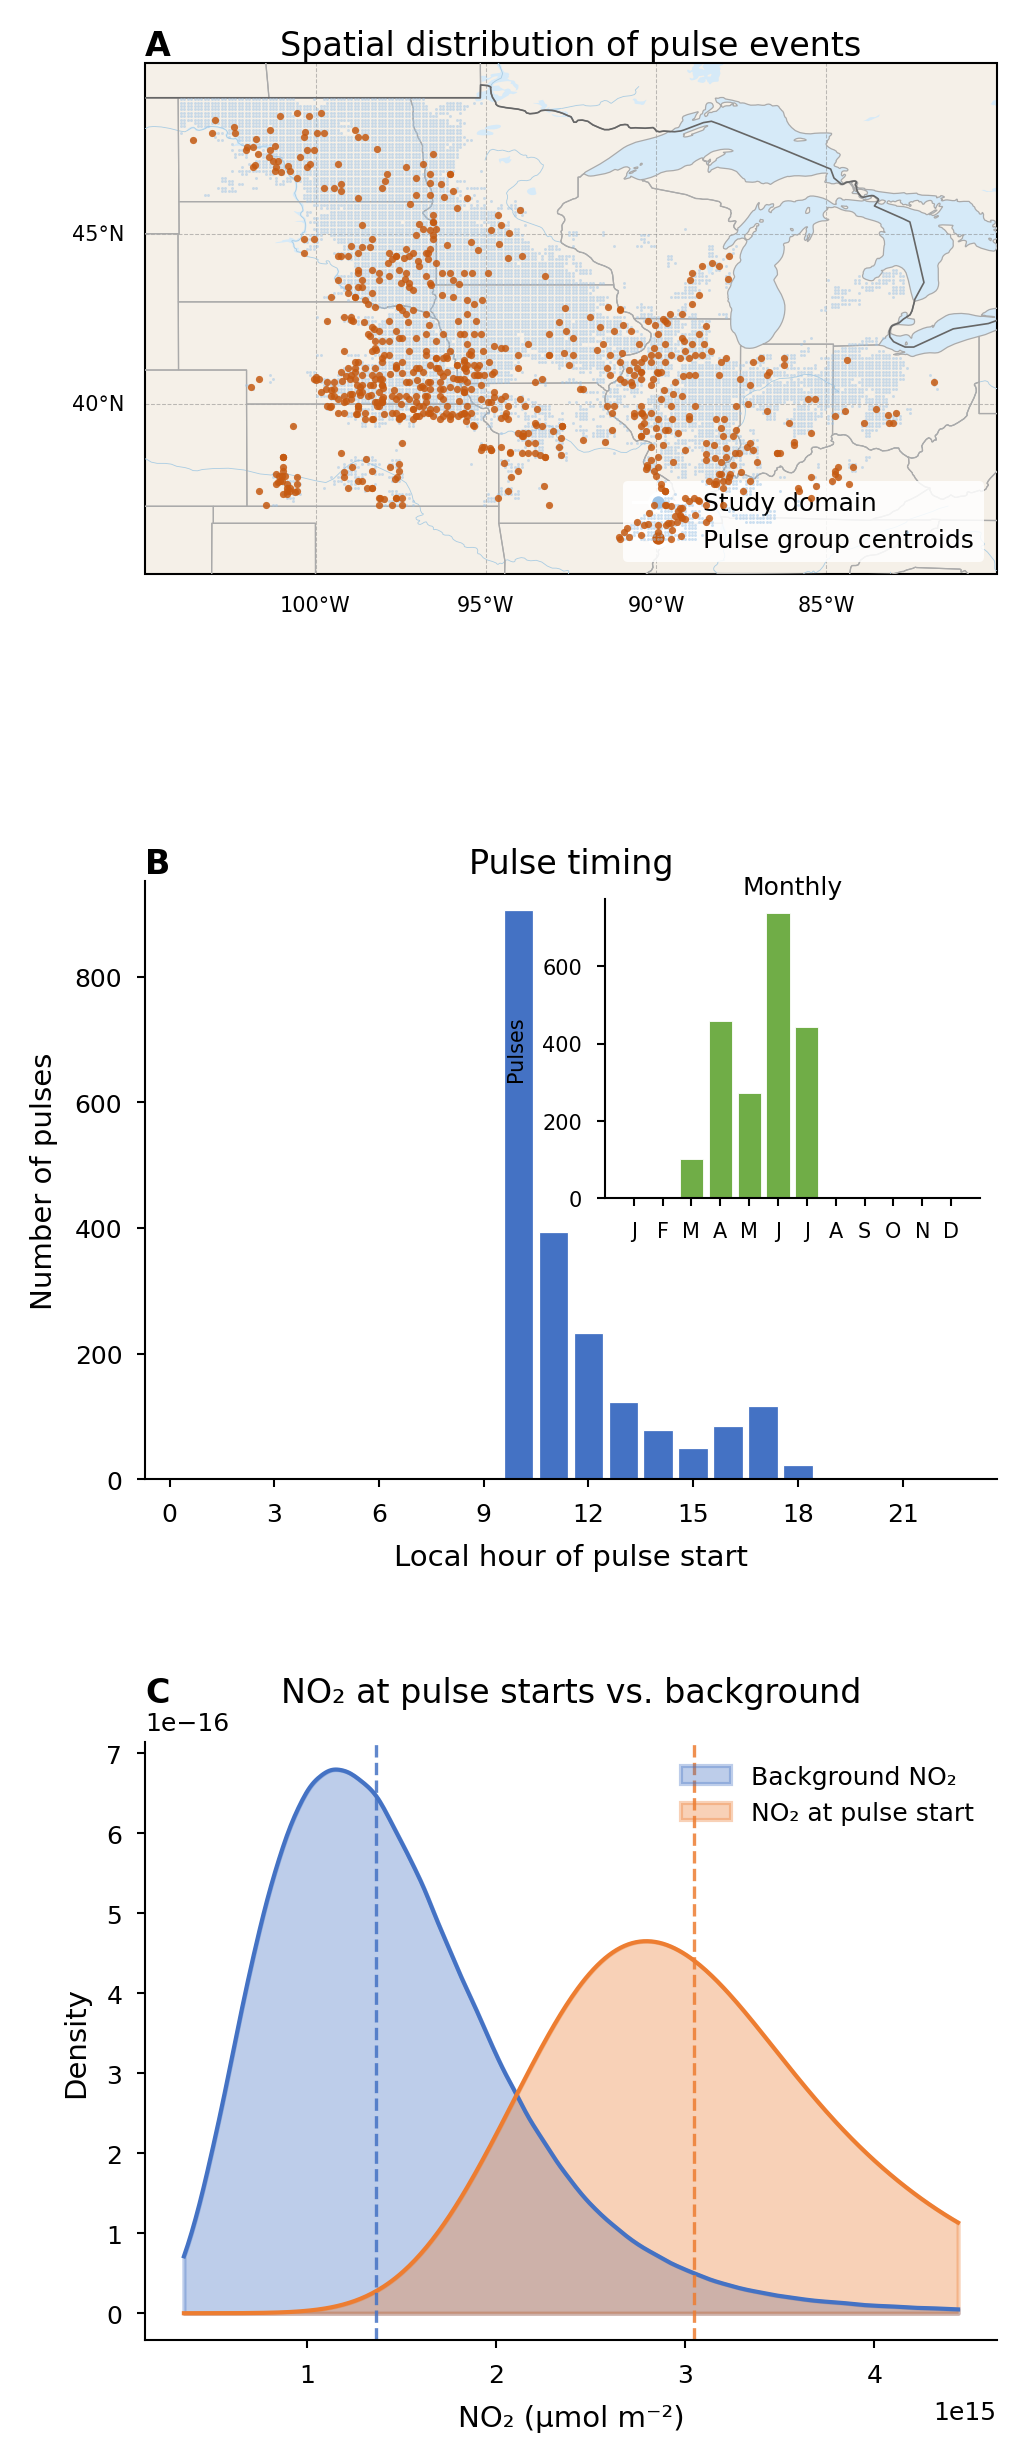

Saved: pulse_3panel_PNAS.pdf / .png


In [32]:
COLOR_DOMAIN = "#9DC3E6"   # light blue   — all study-domain grid cells
COLOR_PULSE  = "#C55A11"   # burnt orange — grouped pulse centroids
COLOR_BG     = "#4472C4"   # blue         — background NO2 KDE
COLOR_START  = "#ED7D31"   # orange       — pulse-start NO2 KDE
COLOR_HIST   = "#4472C4"   # hour-of-day bars
COLOR_BAR    = "#70AD47"   # monthly inset bars

# ── DATA PREPARATION ─────────────────────────────────────────────────────

# --- Pulse-start subset (from df) ----------------------------------------
pulse_df = df[df["pulse_start"] == True].copy()
pulse_df["datetime_local"] = pd.to_datetime(pulse_df["datetime_local"])
pulse_df["_hour"]  = pulse_df["datetime_local"].dt.hour
pulse_df["_month"] = pulse_df["datetime_local"].dt.month

# --- All unique grid cells in the study domain (from df) -----------------
all_cells = df[["grid_lat", "grid_lon"]].drop_duplicates()

# --- One centroid per pulse group (from groups_df) -----------------------
# groups_df has one row per observation within each group; we take the
# mean lat/lon across all rows belonging to each group_id
group_centroids = (
    groups_df.groupby("group_id")[["grid_lat", "grid_lon"]]
    .mean()
    .reset_index()
    .rename(columns={"grid_lat": "centroid_lat", "grid_lon": "centroid_lon"})
)

# --- NO2 arrays for KDE --------------------------------------------------
# Background = all non-pulse-start rows in df
bg_vals    = df.loc[df["pulse_start"] != True, "no2_mean"].dropna().values
start_vals = pulse_df["no2_mean"].dropna().values

# ── FIGURE ───────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(3.42, 8.5), dpi=300)
gs  = gridspec.GridSpec(
    3, 1, figure=fig,
    hspace=0.44,
    top=0.97, bottom=0.06, left=0.14, right=0.97,
)

# ═════════════════════════════════════════════════════════════════════════
# PANEL A — Map (PlateCarree; no PROJ database required)
# ═════════════════════════════════════════════════════════════════════════
proj   = ccrs.PlateCarree()
ax_map = fig.add_subplot(gs[0], projection=proj)
ax_map.set_extent([-105, -80, 35, 50], crs=proj)

# Basemap layers — downloaded & cached automatically on first run
ax_map.add_feature(cfeature.OCEAN.with_scale("50m"),
                   facecolor="#D6EAF8", zorder=0)
ax_map.add_feature(cfeature.LAND.with_scale("50m"),
                   facecolor="#F5F0E8", zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),
                   facecolor="#D6EAF8", linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"),
                   edgecolor="#A9CCE3", linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"),
                   edgecolor="#AAAAAA", linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"),
                   edgecolor="#666666", linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)

# All study-domain grid cells
ax_map.scatter(
    all_cells["grid_lon"], all_cells["grid_lat"],
    s=0.5, c=COLOR_DOMAIN, alpha=0.5, linewidths=0,
    transform=proj, zorder=7,
)
# Grouped pulse centroids
ax_map.scatter(
    group_centroids["centroid_lon"], group_centroids["centroid_lat"],
    s=3, c=COLOR_PULSE, alpha=0.85, linewidths=0,
    transform=proj, zorder=8,
)

gl = ax_map.gridlines(
    draw_labels=True, linewidth=0.25, color="gray",
    alpha=0.5, linestyle="--",
    xlocs=range(-110, -75, 5), ylocs=range(35, 55, 5),
)
gl.top_labels   = False
gl.right_labels = False
gl.xlabel_style = {"size": 5}
gl.ylabel_style = {"size": 5}

legend_els = [
    Line2D([0],[0], marker="o", color="w", markerfacecolor=COLOR_DOMAIN,
           markersize=4, label="Study domain"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor=COLOR_PULSE,
           markersize=4, label="Pulse group centroids"),
]
ax_map.legend(handles=legend_els, loc="lower right",
              frameon=True, framealpha=0.85, edgecolor="none")
ax_map.set_title("A", loc="left", fontweight="bold", pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

# ═════════════════════════════════════════════════════════════════════════
# PANEL B — Pulse timing: hour-of-day bars + monthly inset
# ═════════════════════════════════════════════════════════════════════════
ax_timing = fig.add_subplot(gs[1])

hour_counts = pulse_df["_hour"].value_counts().sort_index()
ax_timing.bar(
    hour_counts.index, hour_counts.values,
    width=0.85, color=COLOR_HIST, edgecolor="white", linewidth=0.3,
)
ax_timing.set_xlabel("Local hour of pulse start")
ax_timing.set_ylabel("Number of pulses")
ax_timing.set_xlim(-0.7, 23.7)
ax_timing.set_xticks([0, 3, 6, 9, 12, 15, 18, 21])
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.set_title("B", loc="left", fontweight="bold", pad=2)
ax_timing.set_title("Pulse timing", pad=2)

# Monthly inset
mc = (pulse_df["_month"]
      .value_counts()
      .sort_index()
      .reindex(range(1, 13), fill_value=0))
inset = ax_timing.inset_axes([0.54, 0.47, 0.44, 0.50])
inset.bar(range(12), mc.values, color=COLOR_BAR, edgecolor="white", linewidth=0.2)
inset.set_xticks(range(12))
inset.set_xticklabels(
    ["J","F","M","A","M","J","J","A","S","O","N","D"], fontsize=5
)
inset.tick_params(axis="y", labelsize=5)
inset.set_ylabel("Pulses", fontsize=5)
inset.spines[["top", "right"]].set_visible(False)
inset.set_title("Monthly", fontsize=6, pad=1)

# ═════════════════════════════════════════════════════════════════════════
# PANEL C — KDE: background NO2 vs NO2 at pulse starts
# ═════════════════════════════════════════════════════════════════════════
ax_kde = fig.add_subplot(gs[2])

lo = np.percentile(np.concatenate([bg_vals, start_vals]), 0.5)
hi = np.percentile(np.concatenate([bg_vals, start_vals]), 99.5)
x  = np.linspace(lo, hi, 400)

kde_bg    = gaussian_kde(bg_vals,    bw_method="scott")
kde_start = gaussian_kde(start_vals, bw_method="scott")

ax_kde.fill_between(x, kde_bg(x),    alpha=0.35, color=COLOR_BG,
                    label="Background NO₂")
ax_kde.fill_between(x, kde_start(x), alpha=0.35, color=COLOR_START,
                    label="NO₂ at pulse start")
ax_kde.plot(x, kde_bg(x),    color=COLOR_BG,    linewidth=1.0)
ax_kde.plot(x, kde_start(x), color=COLOR_START, linewidth=1.0)

for vals, color in [(bg_vals, COLOR_BG), (start_vals, COLOR_START)]:
    ax_kde.axvline(np.median(vals), color=color,
                   linewidth=0.8, linestyle="--", alpha=0.85)

ax_kde.set_xlabel("NO₂ (µmol m⁻²)")   # update units if yours differ
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C", loc="left", fontweight="bold", pad=2)
ax_kde.set_title("NO₂ at pulse starts vs. background", pad=2)

# ── SAVE ─────────────────────────────────────────────────────────────────
fig.savefig("pulse_3panel_PNAS.pdf", dpi=300, bbox_inches="tight")
fig.savefig("pulse_3panel_PNAS.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pulse_3panel_PNAS.pdf / .png")